In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [1]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi




/home/wx2203/anaconda3/lib/python3.7/site-packages/pandas/compat/_optional.py:138: UserWarning: Pandas requires version '2.7.0' or newer of 'numexpr' (version '2.6.9' currently installed).
  warnings.warn(msg, UserWarning)

Bad key text.latex.preview in file /home/wx2203/anaconda3/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test.mplstyle, line 123 ('text.latex.preview : False')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.5.3/matplotlibrc.template
or from the matplotlib source distribution

Bad key mathtext.fallback_to_cm in file /home/wx2203/anaconda3/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test.mplstyle, line 155 ('mathtext.fallback_to_cm : True  # When True, use symbols from the Computer Modern')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.5.3/matplotlibrc.template
or from the matplotlib source distribution

Ba

# 1. spontaneous running

In [2]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
prefix = '/scratch/' #for s1n3/4
neural_root = str(STEPS / "step_2") + "/"
step_0_root = str(STEPS / "step_0") + "/"
rotary_root = '/home/wx2203/RS_analysis/H_b_new/'
mid_product_root = '/home/wx2203/RS_analysis/behavior2/trash'
dlc_root = '/home/wx2203/RS_analysis/DLC/'
whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
pupil_path = '/home/wx2203/RS_analysis/DLC/updated_pupil/pupil_128_07042020.mat'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'
groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
config_root = '/home/wx2203/Weihao/data_locker/step_0/'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'

mouse='cm128'

In [3]:
f1 = [f for f in glob.glob(neural_root + "*128/[1-3]/H_*[B-J]*.mat", recursive=True)] # runB rotary bug
# f2 = list(set(glob.glob(neural_root+"*128/[4-7]/H_*[B-D]*.mat")) 
#           - set(glob.glob(neural_root+"*128/[5]/H_*B*.mat")))
# f3 = [f for f in glob.glob(neural_root + "*128/[4-7]/H_*[H-J]*.mat", recursive=True)]

file_spont = f1
file_spont

['/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runI_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runG_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runJ_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runH_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runE_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runC_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runD_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runB_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/2/H_runF_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128/3/H_runI_stim_1.mat',
 '/scratch/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm128

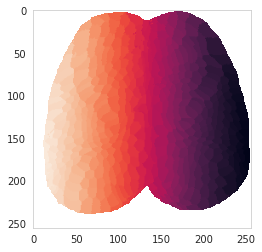

In [4]:
with h5py.File(step_0_root+'idx_sorted_500_cm128.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [5]:
fetch_sensory_path = str(PREPARES / "sensory-boop-test") + "/"
sensory_ind = load_pickle(fetch_sensory_path+'inferred_brightest_ind_'+mouse)
mouth_S1_ind = sensory_ind['mouth']

In [6]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False


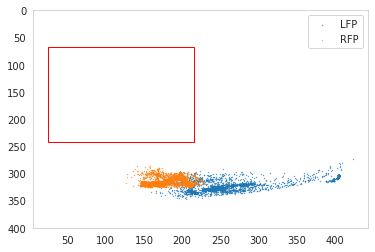

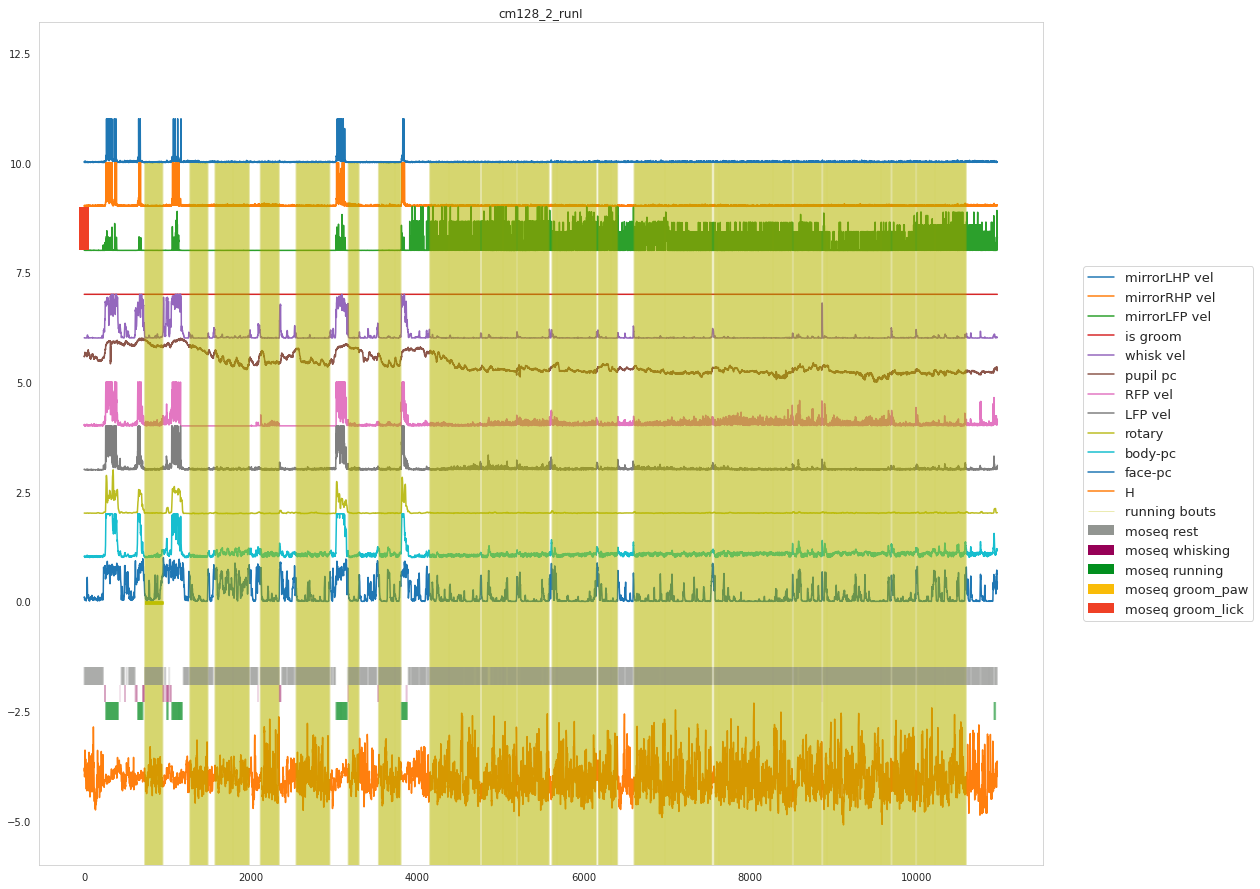

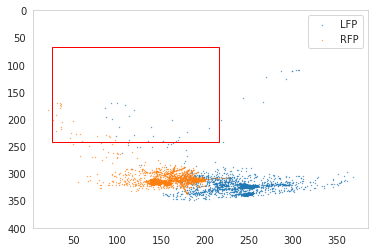

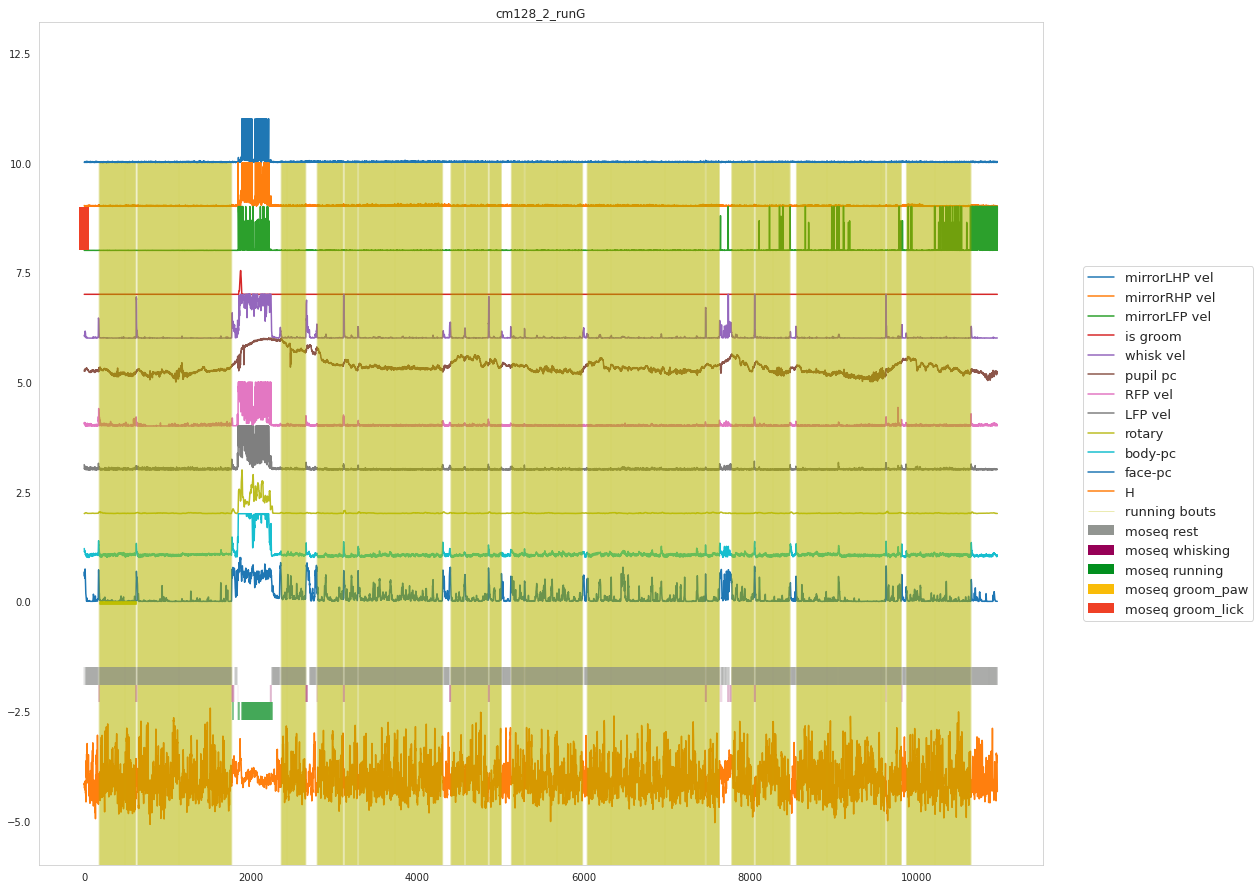

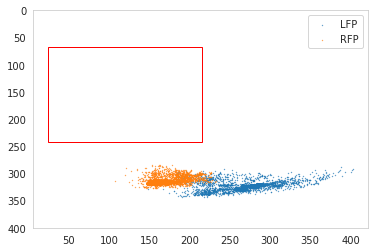

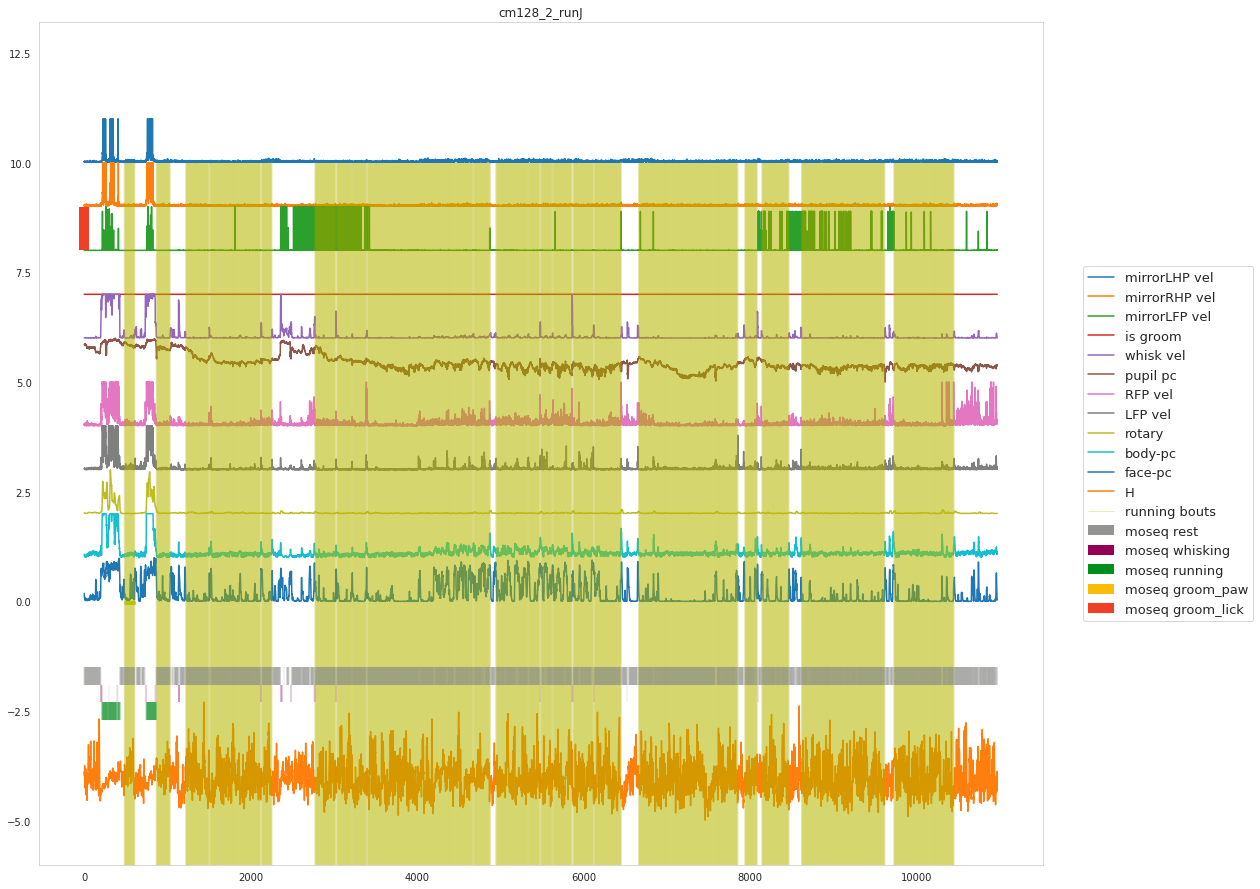

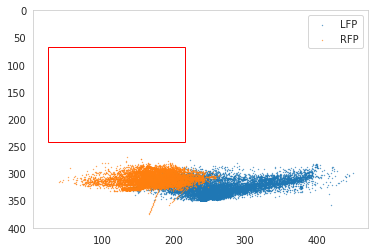

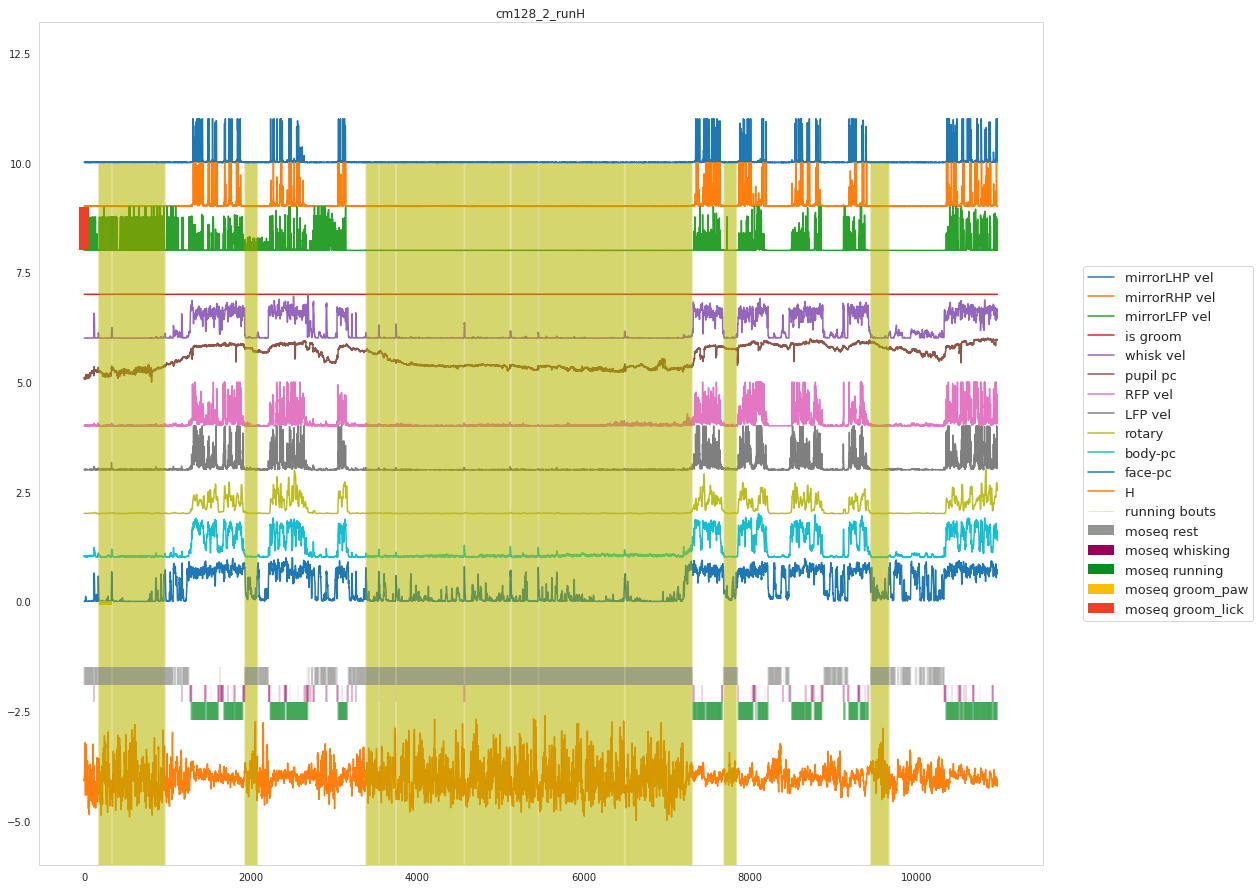

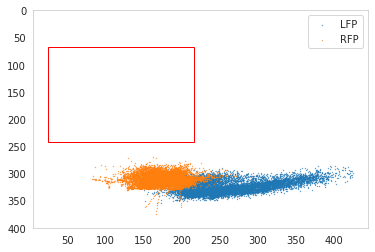

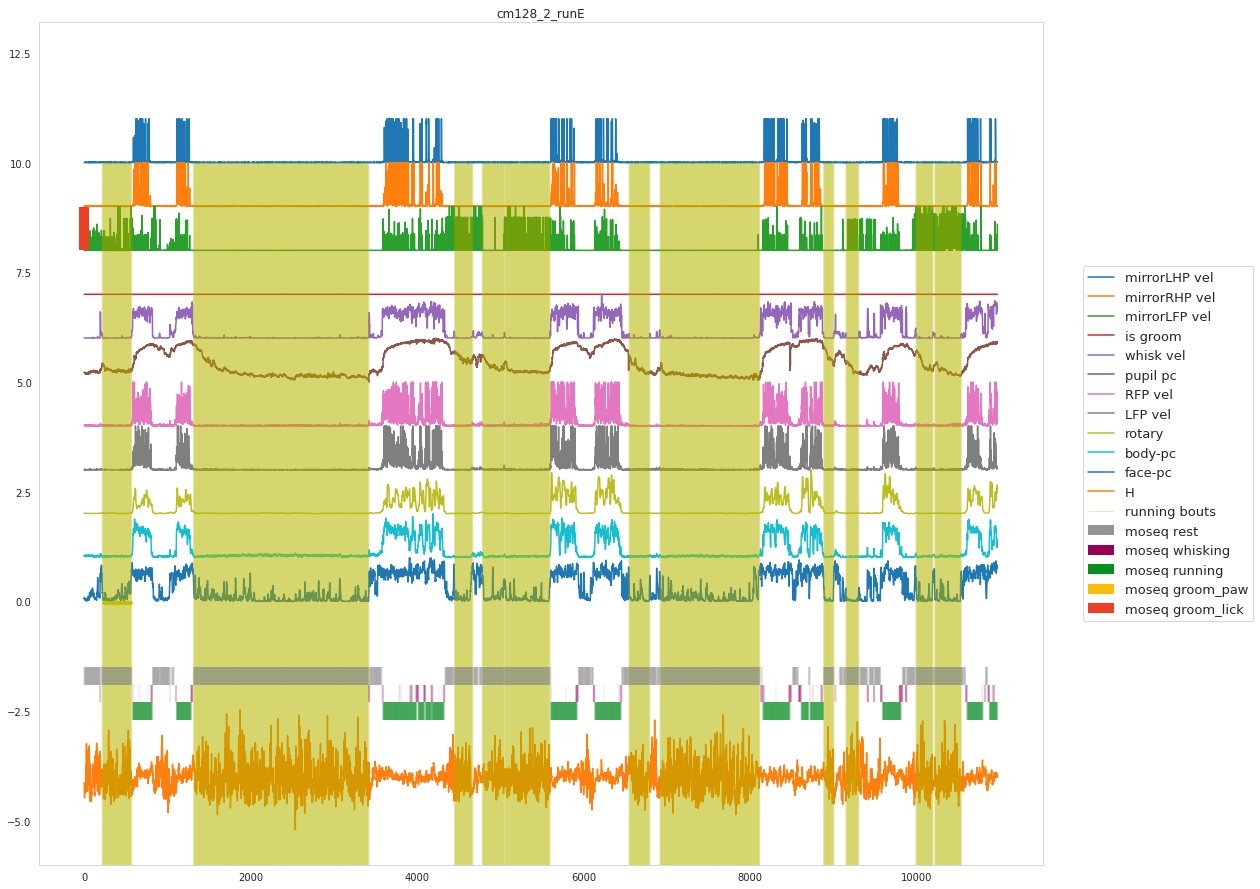

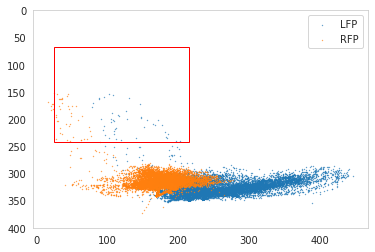

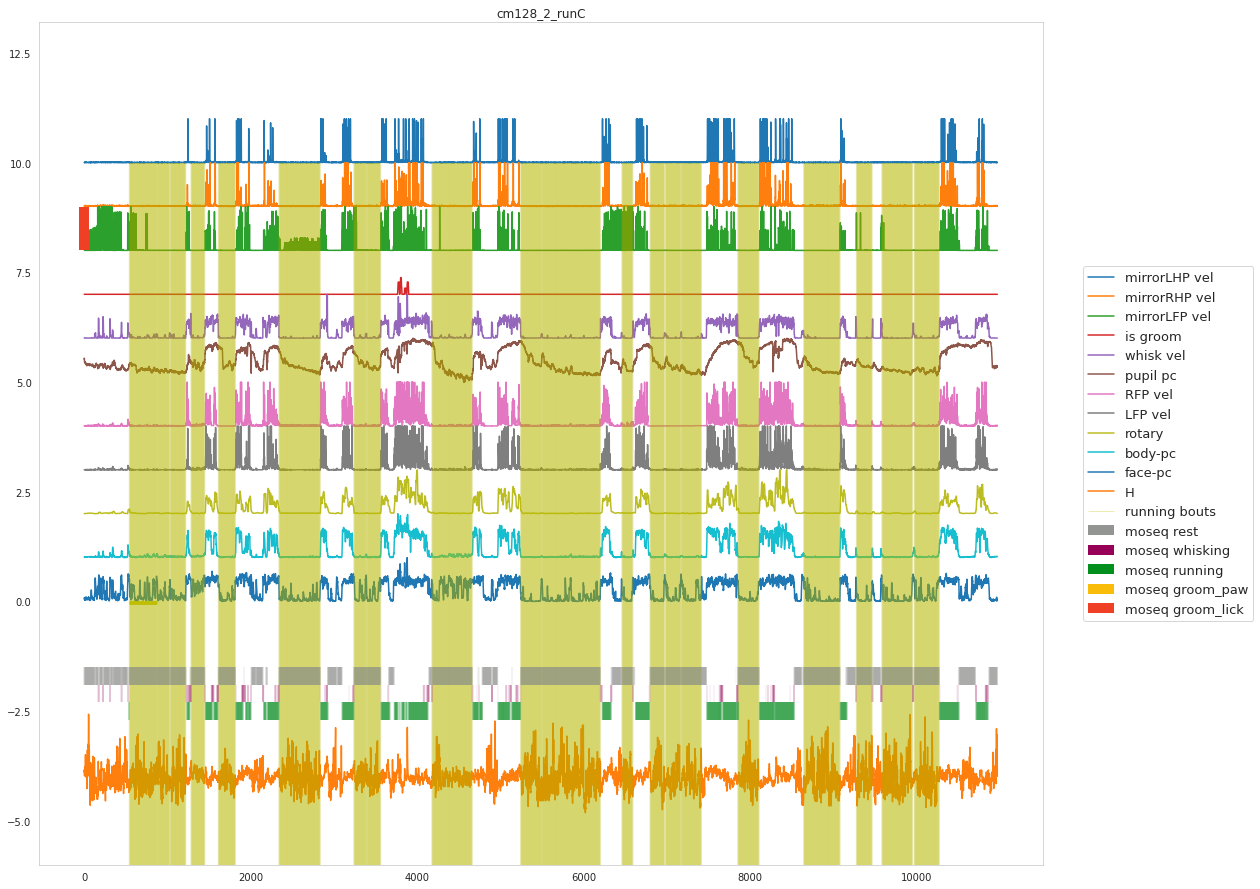

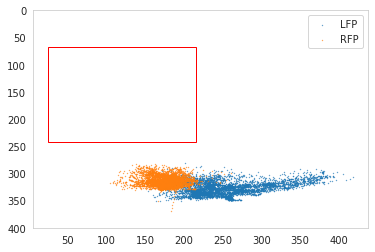

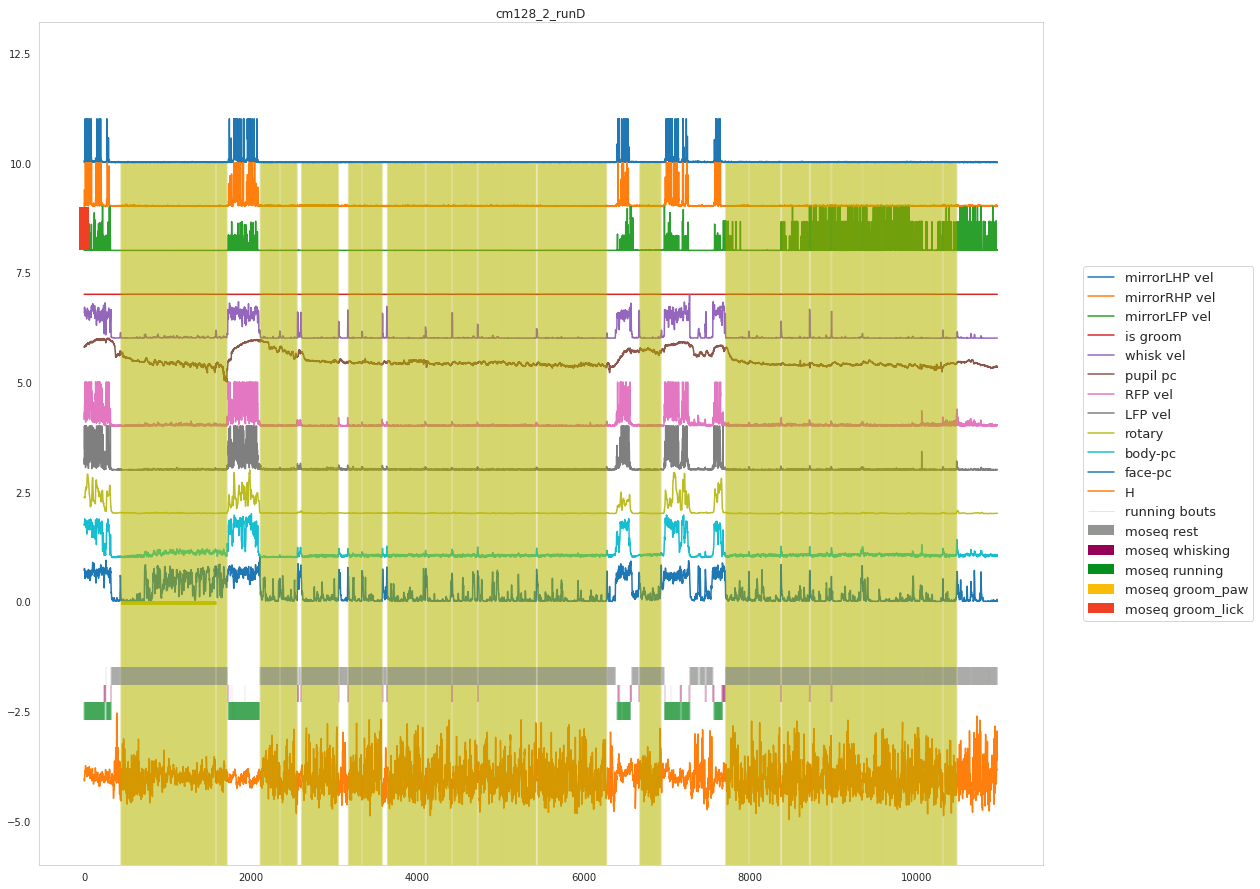

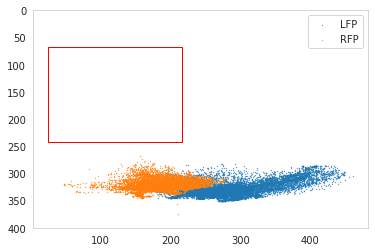

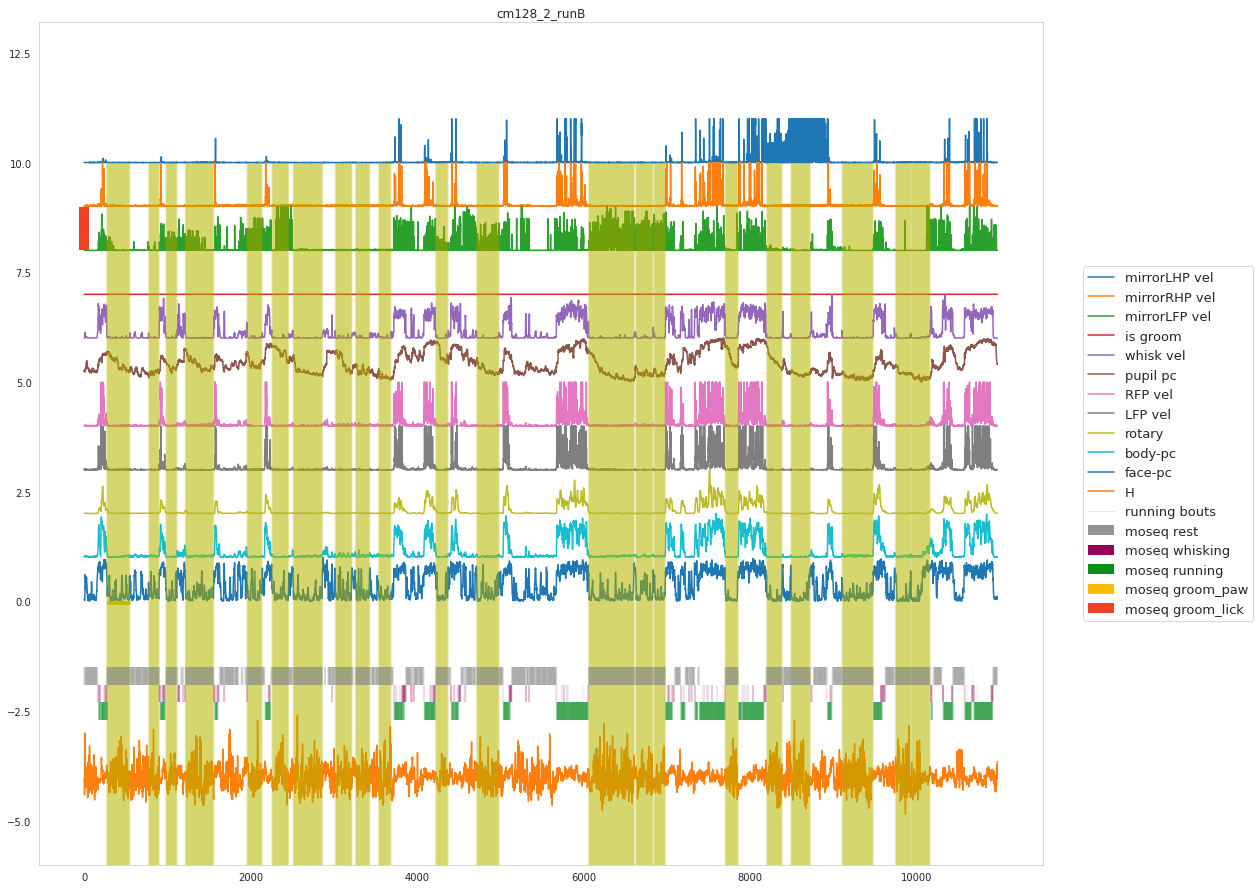

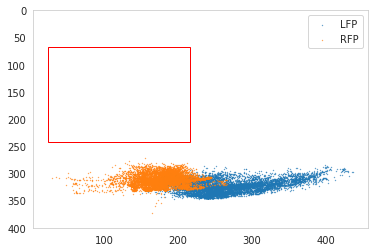

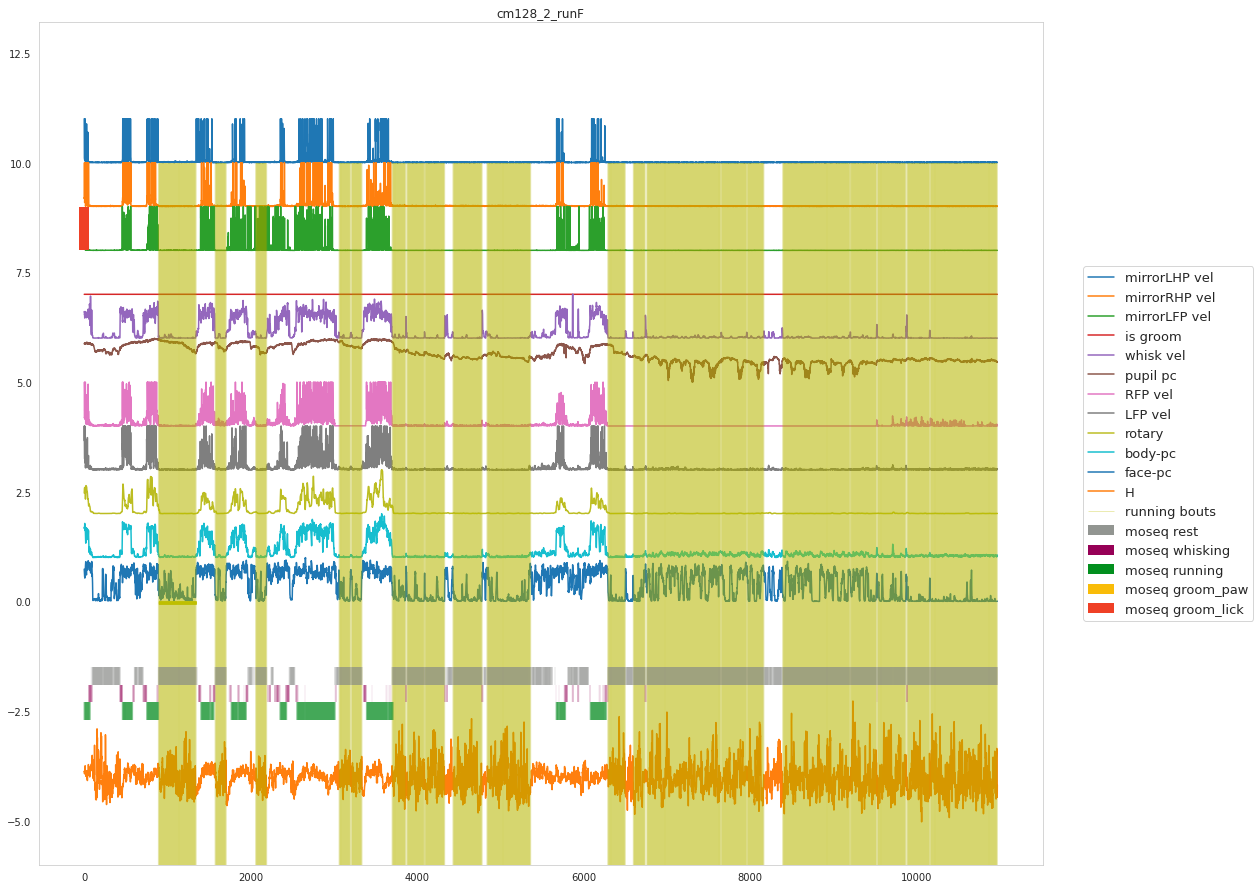

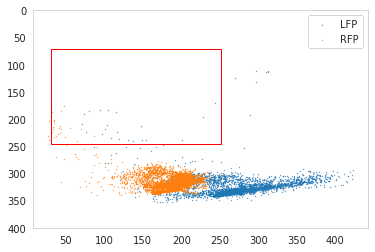

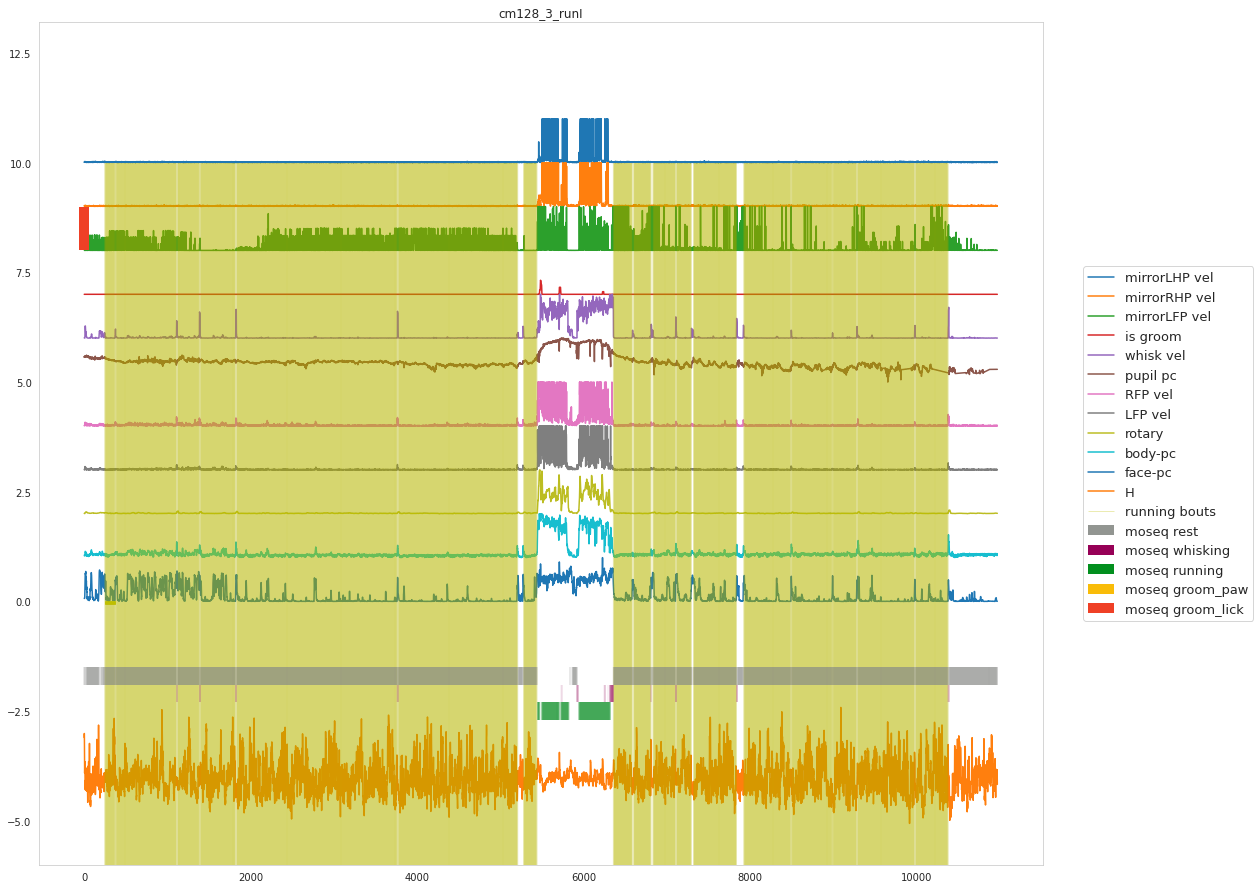

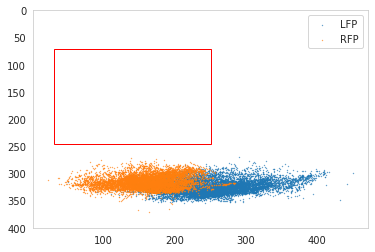

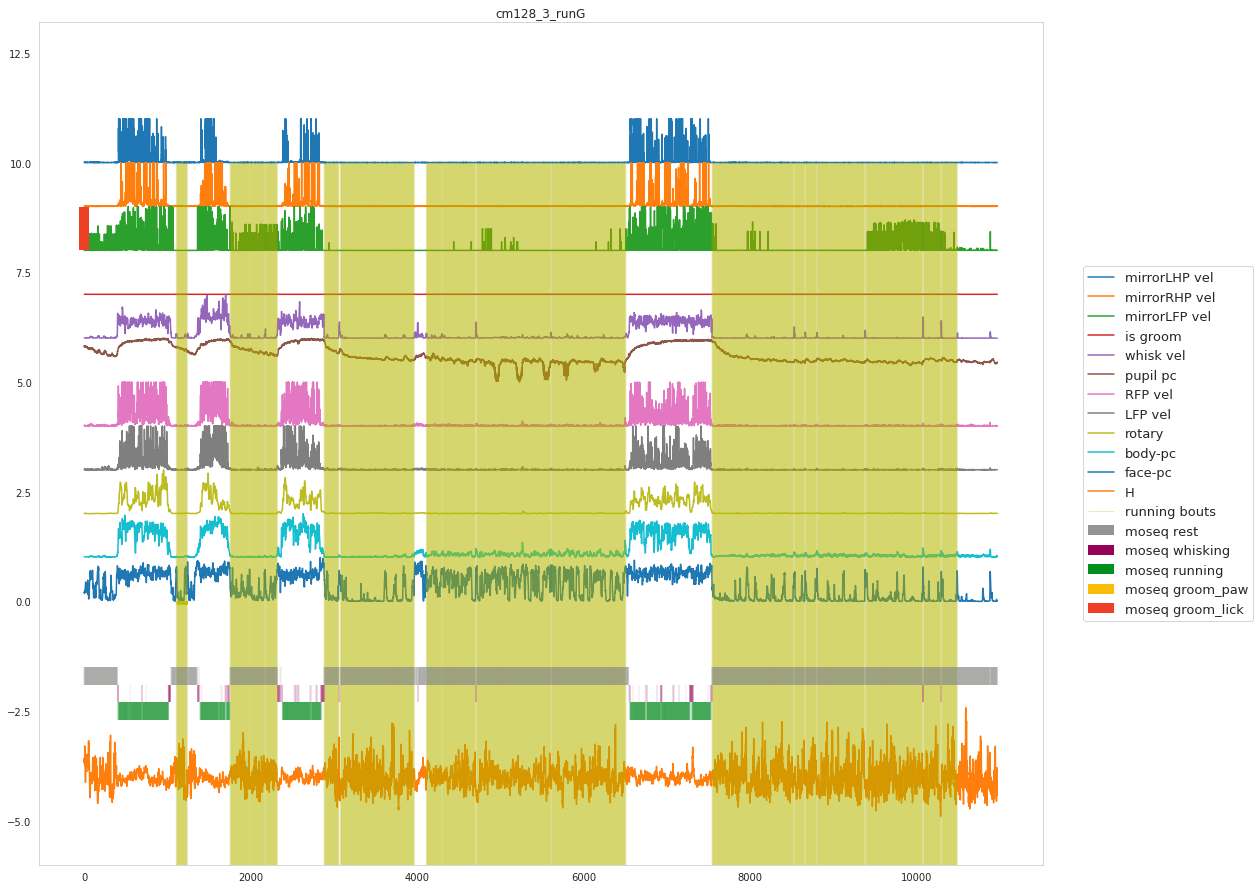

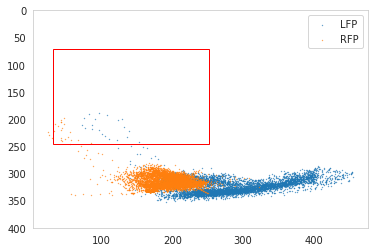

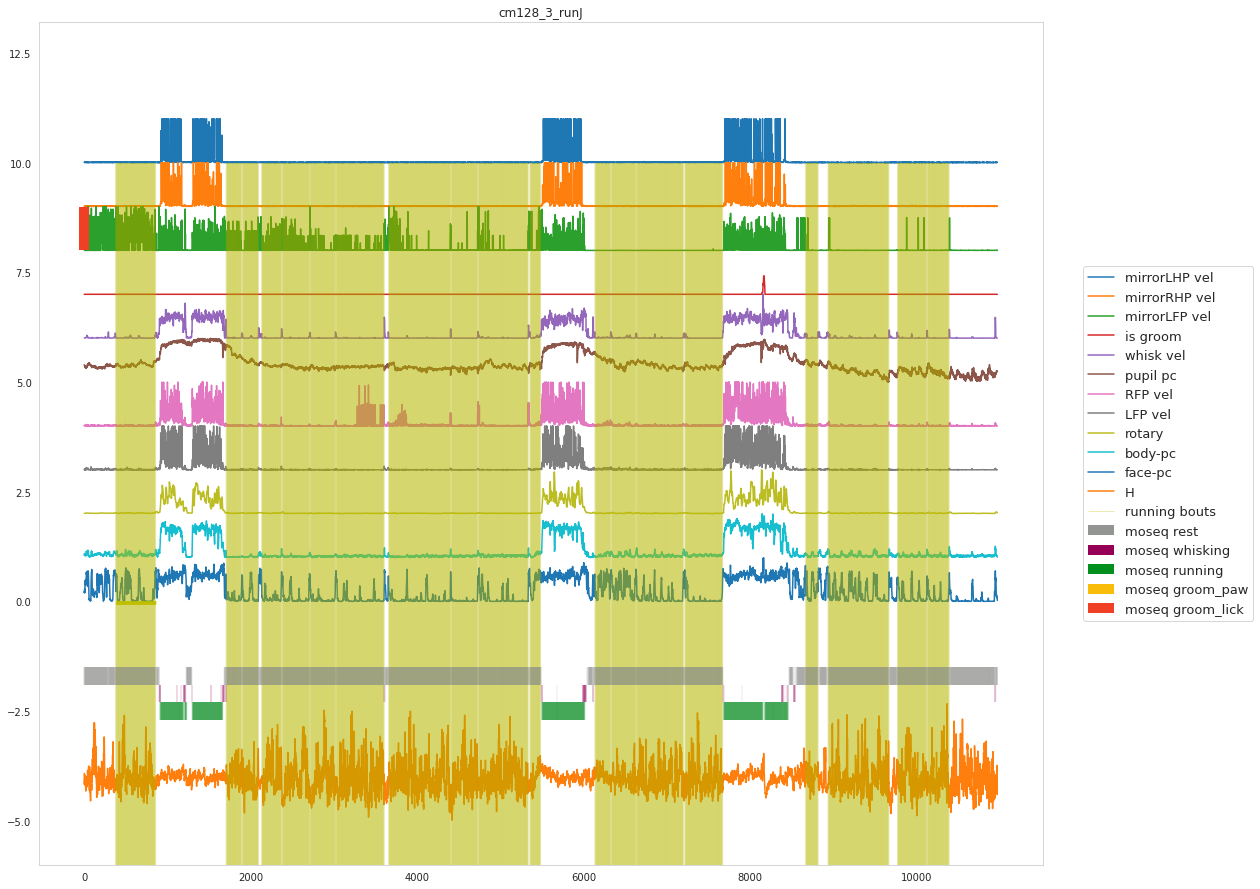

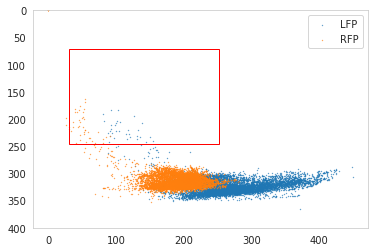

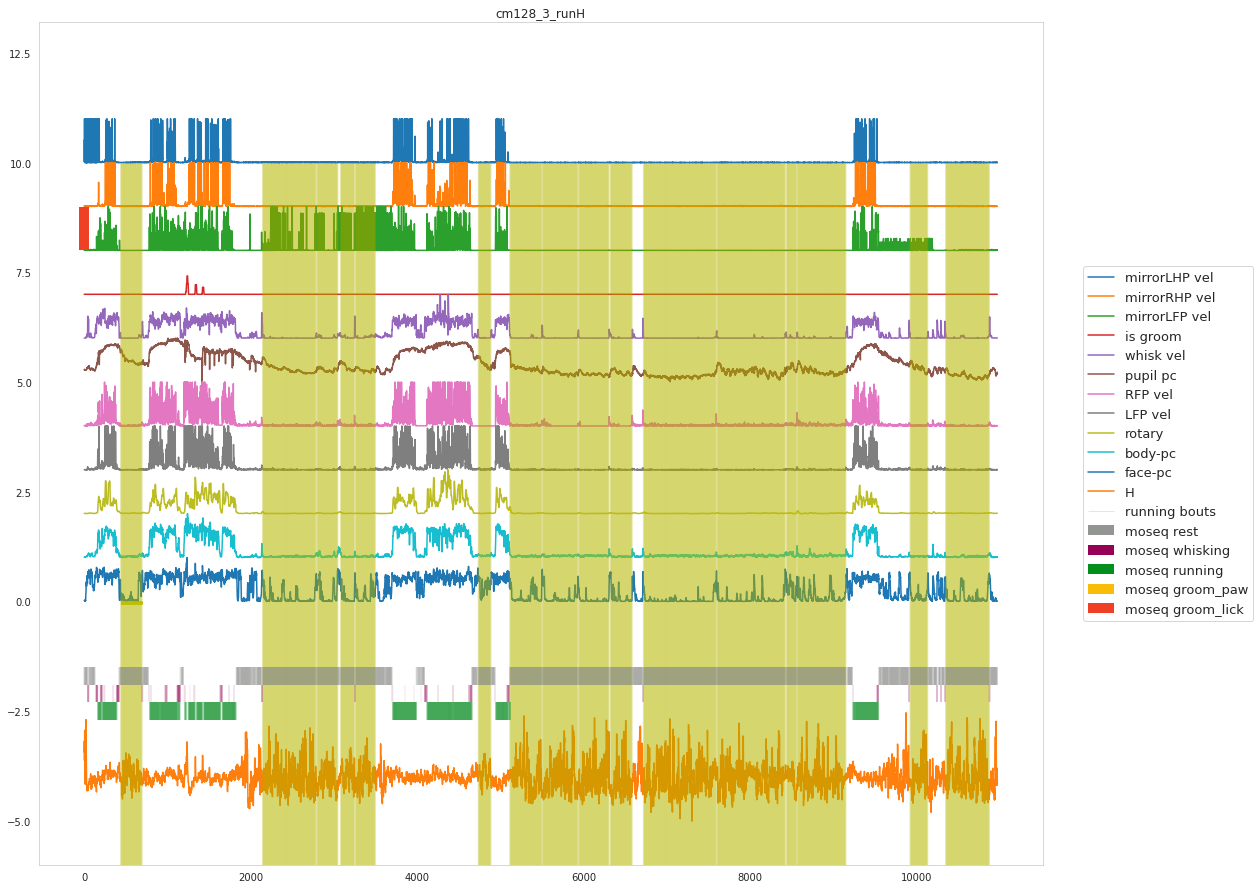

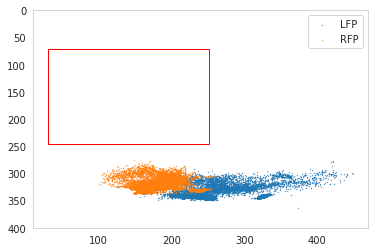

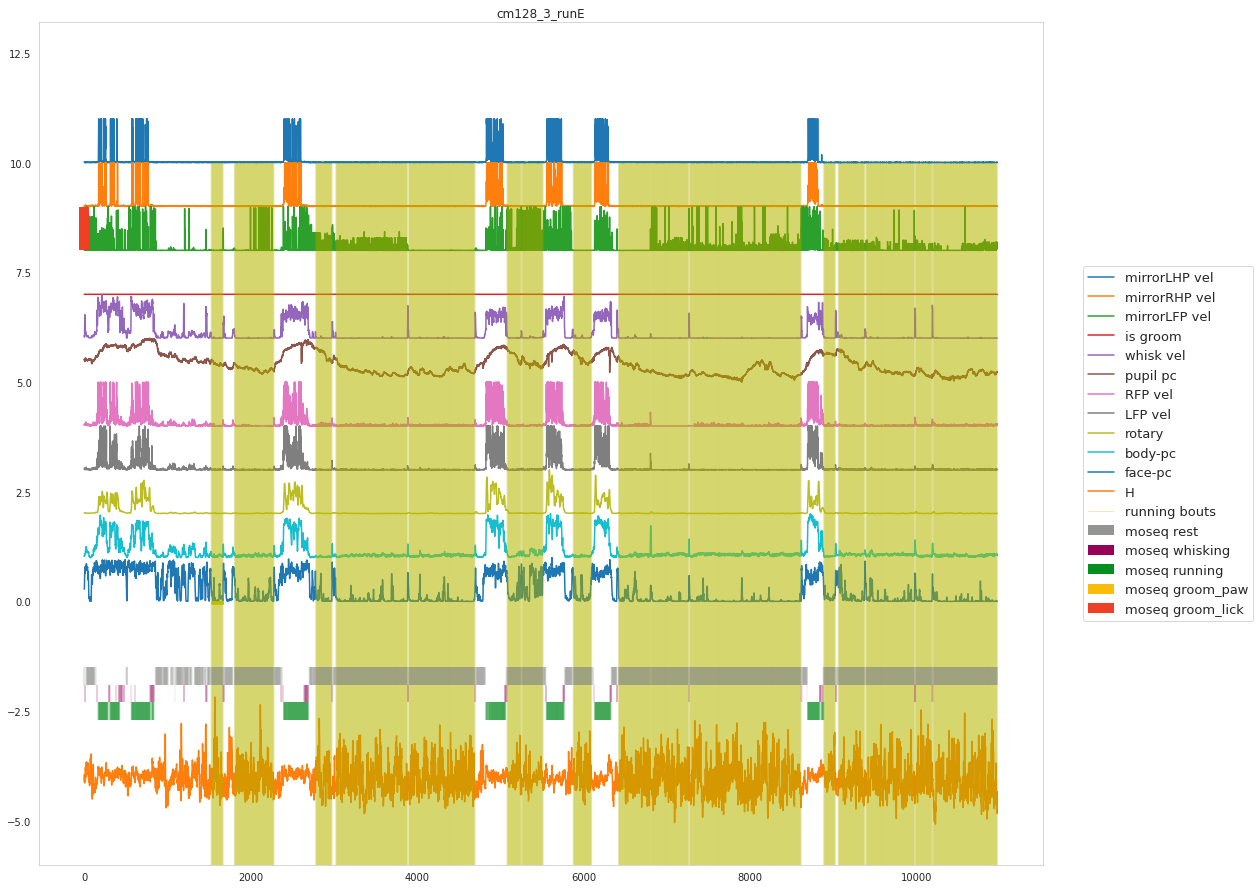

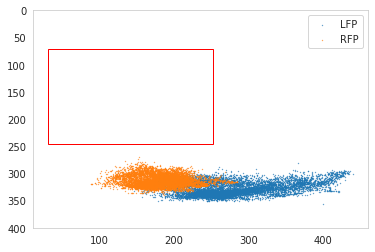

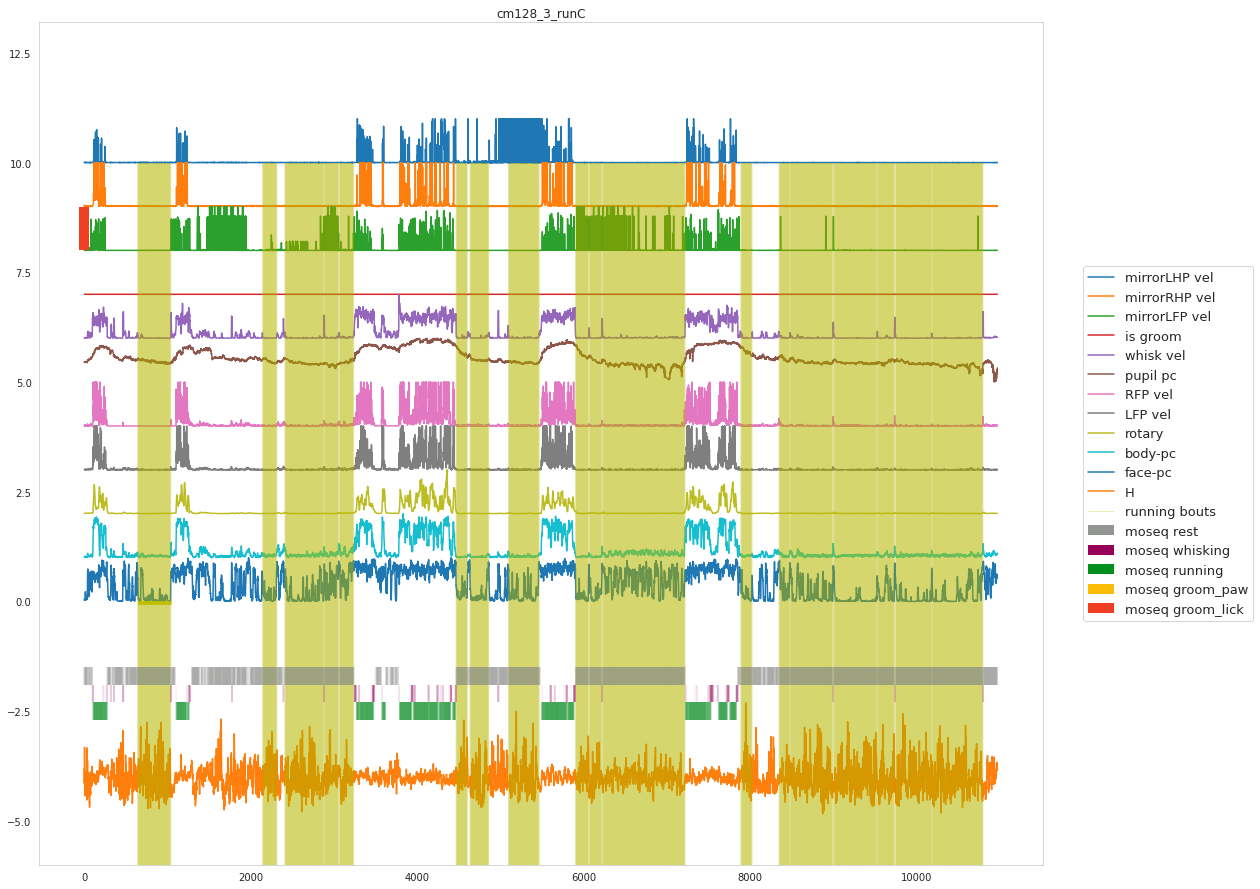

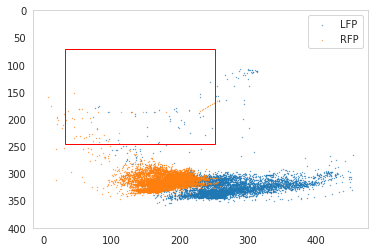

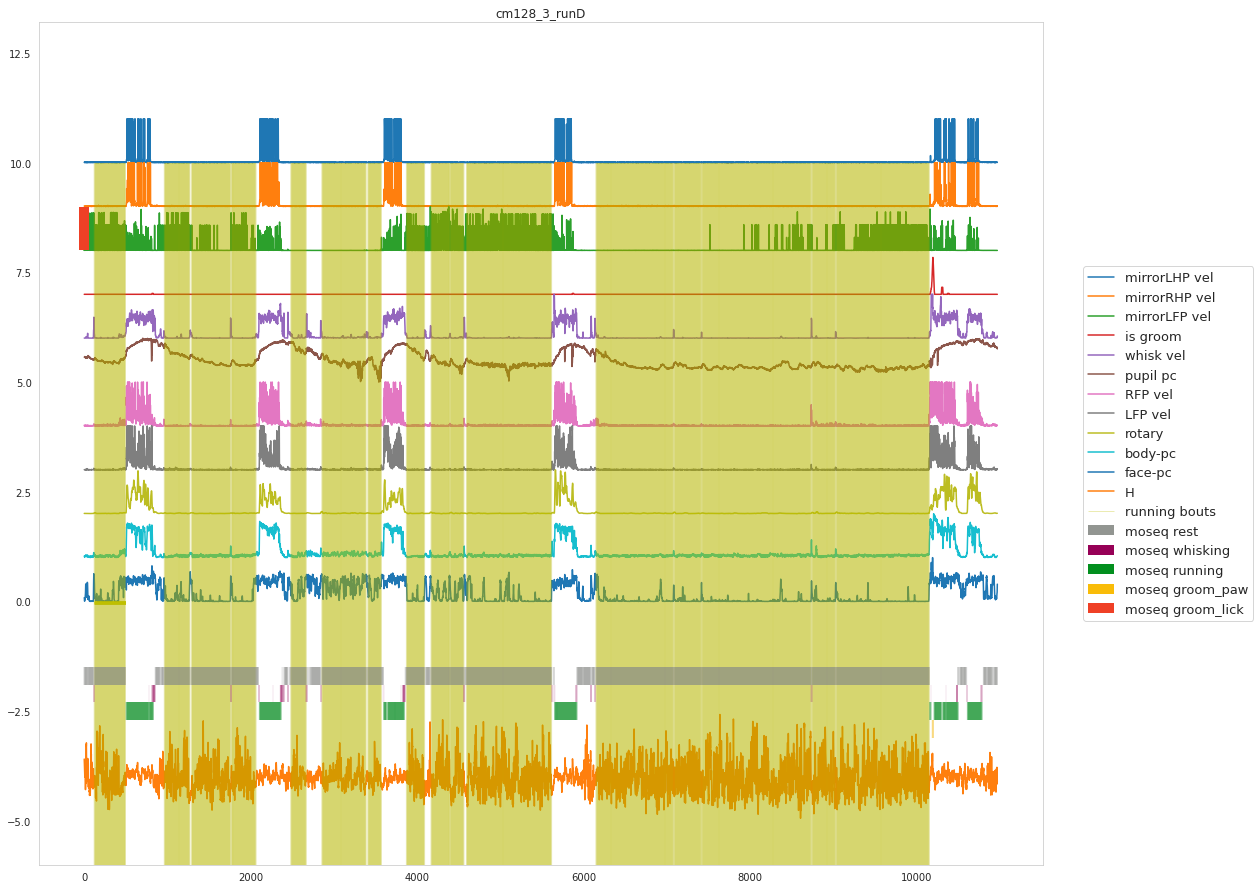

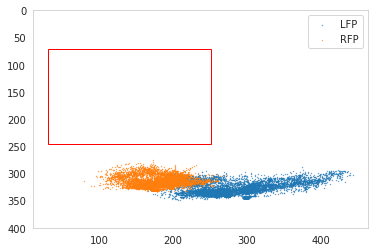

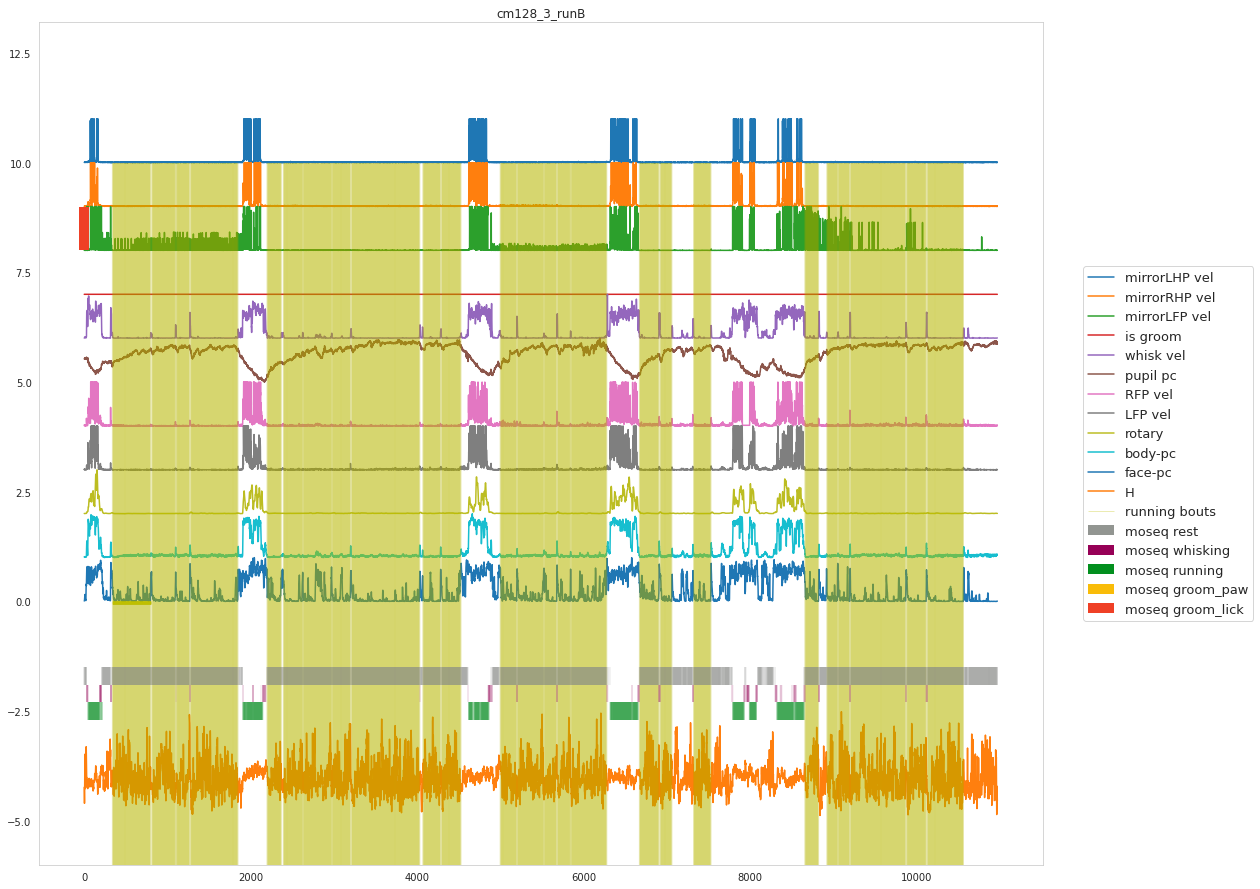

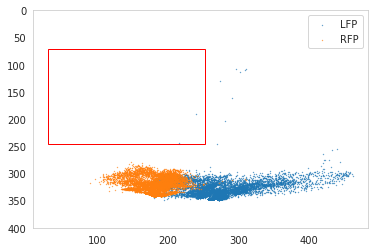

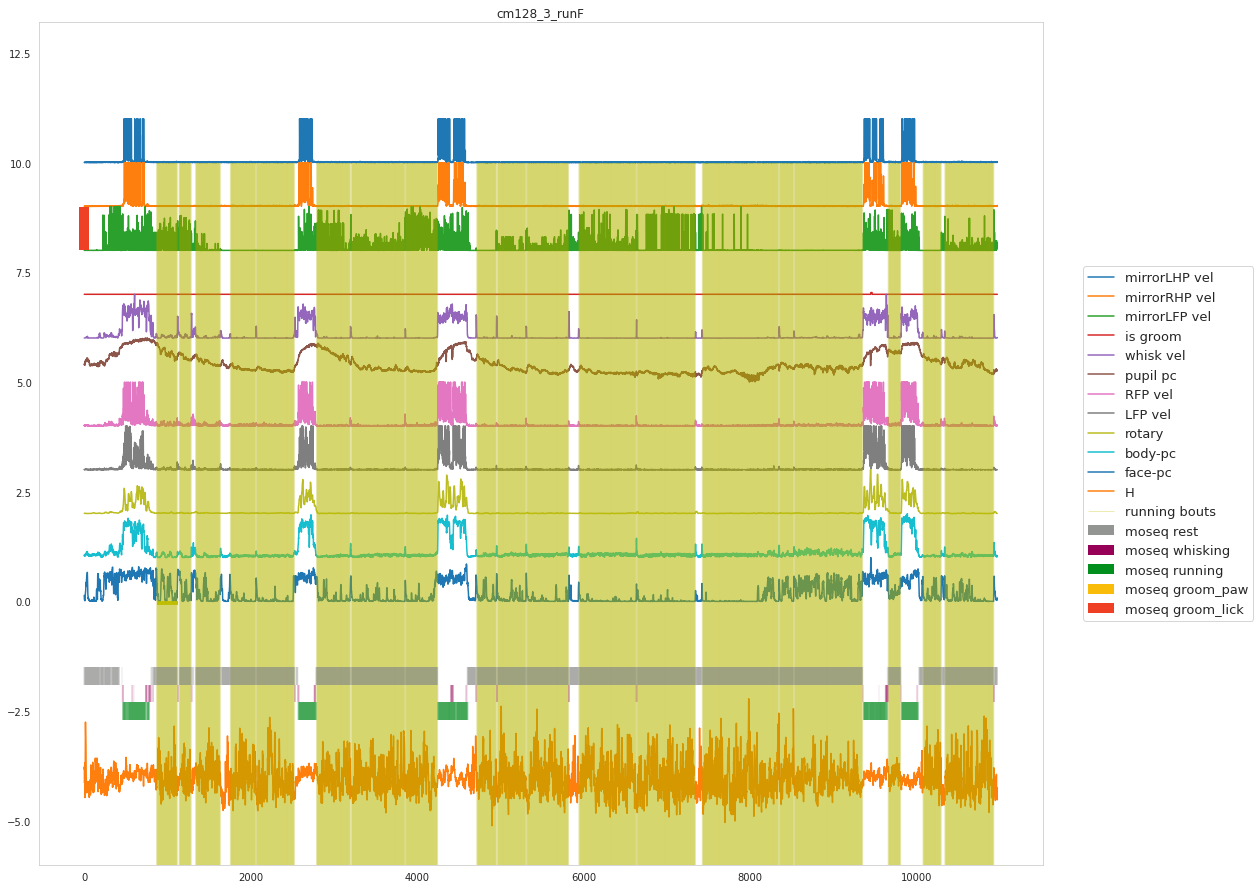

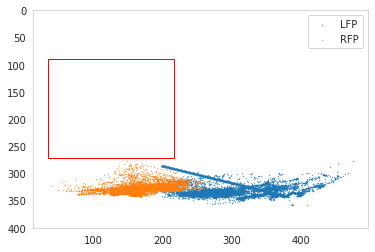

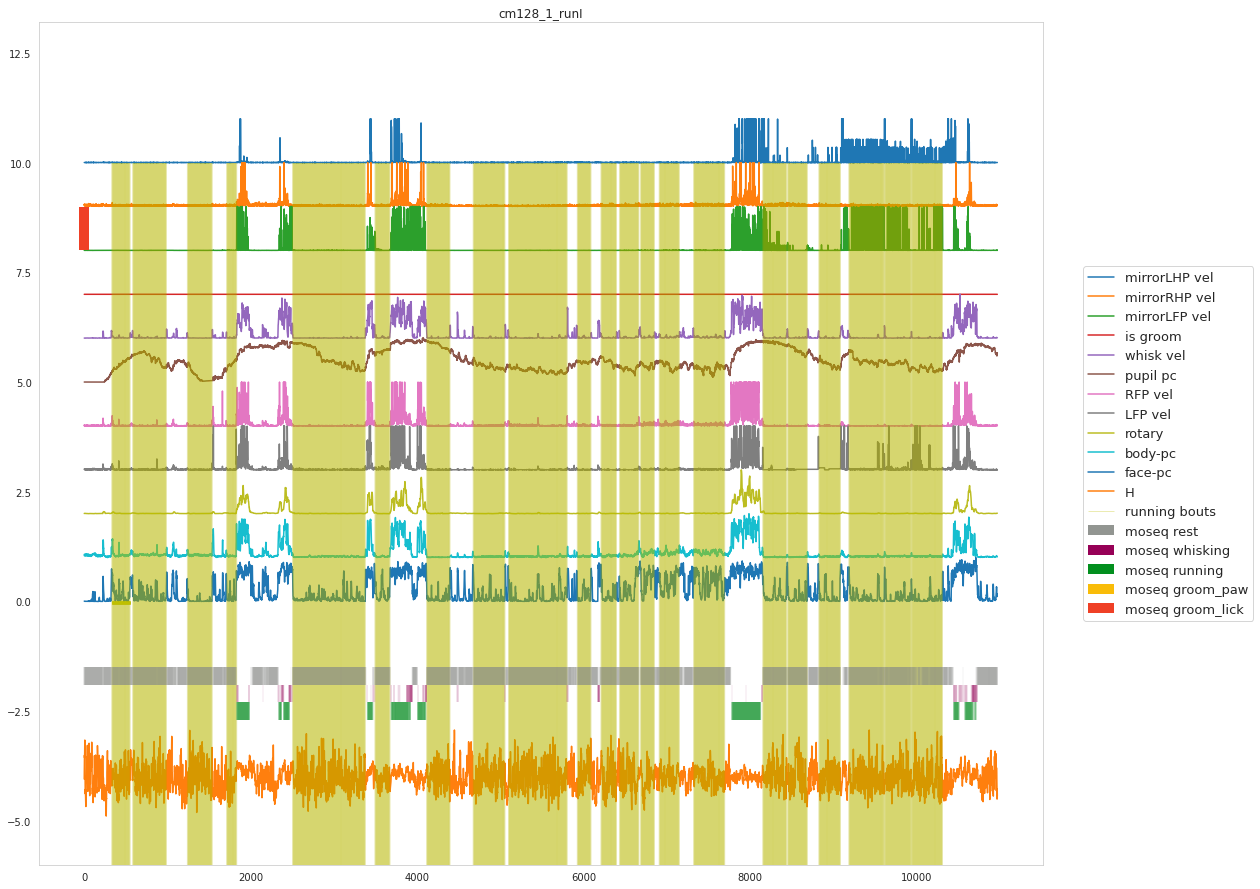

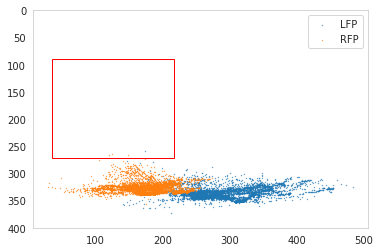

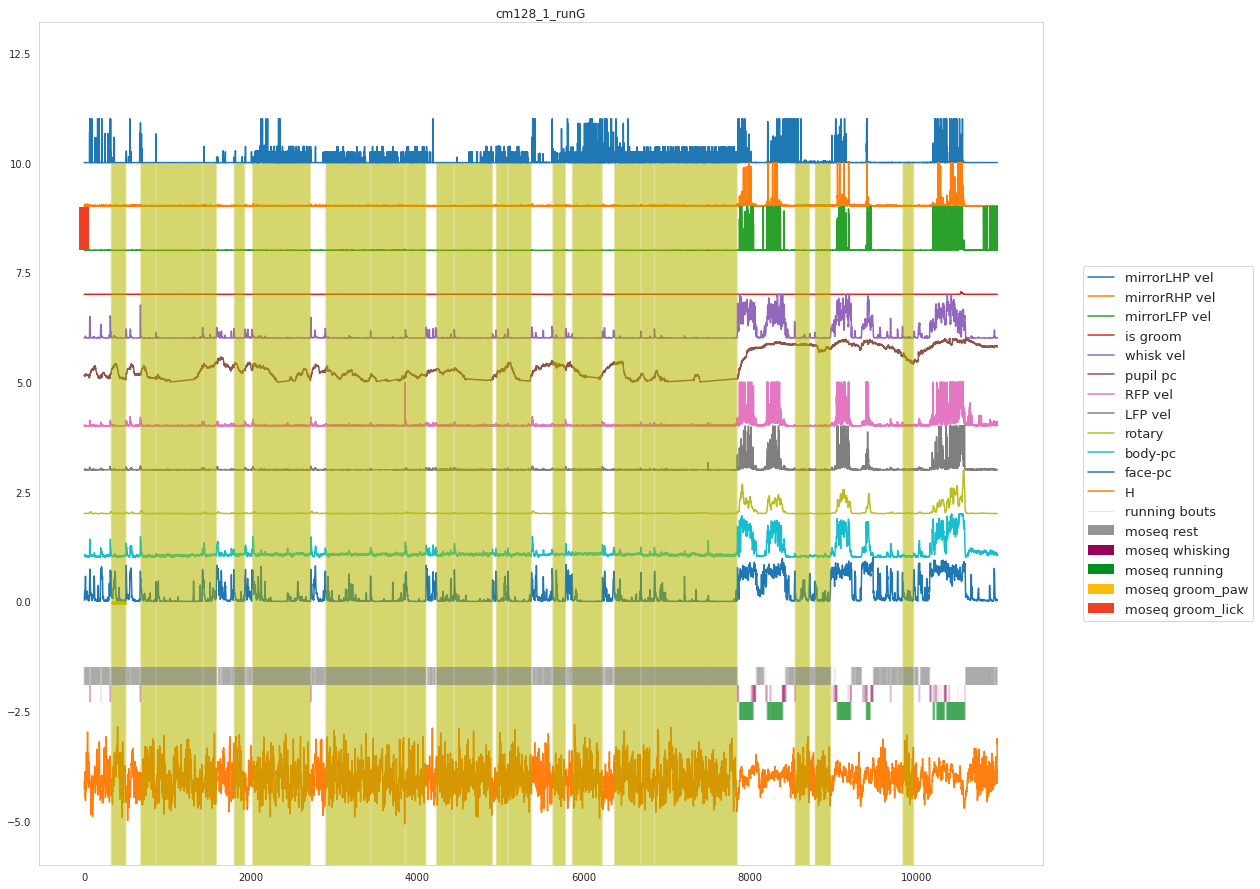

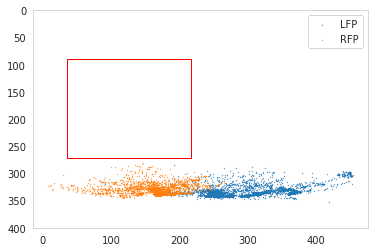

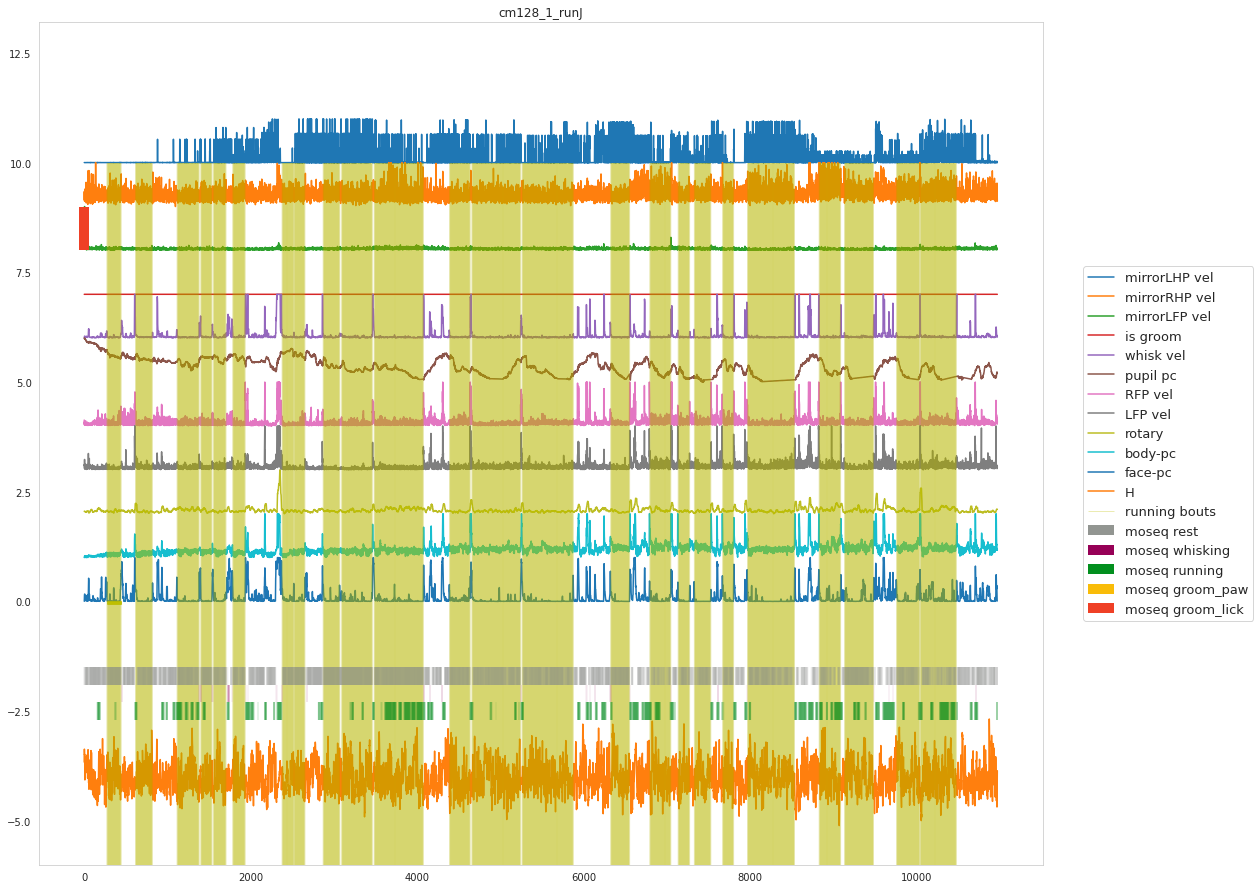

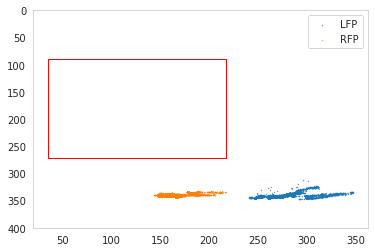

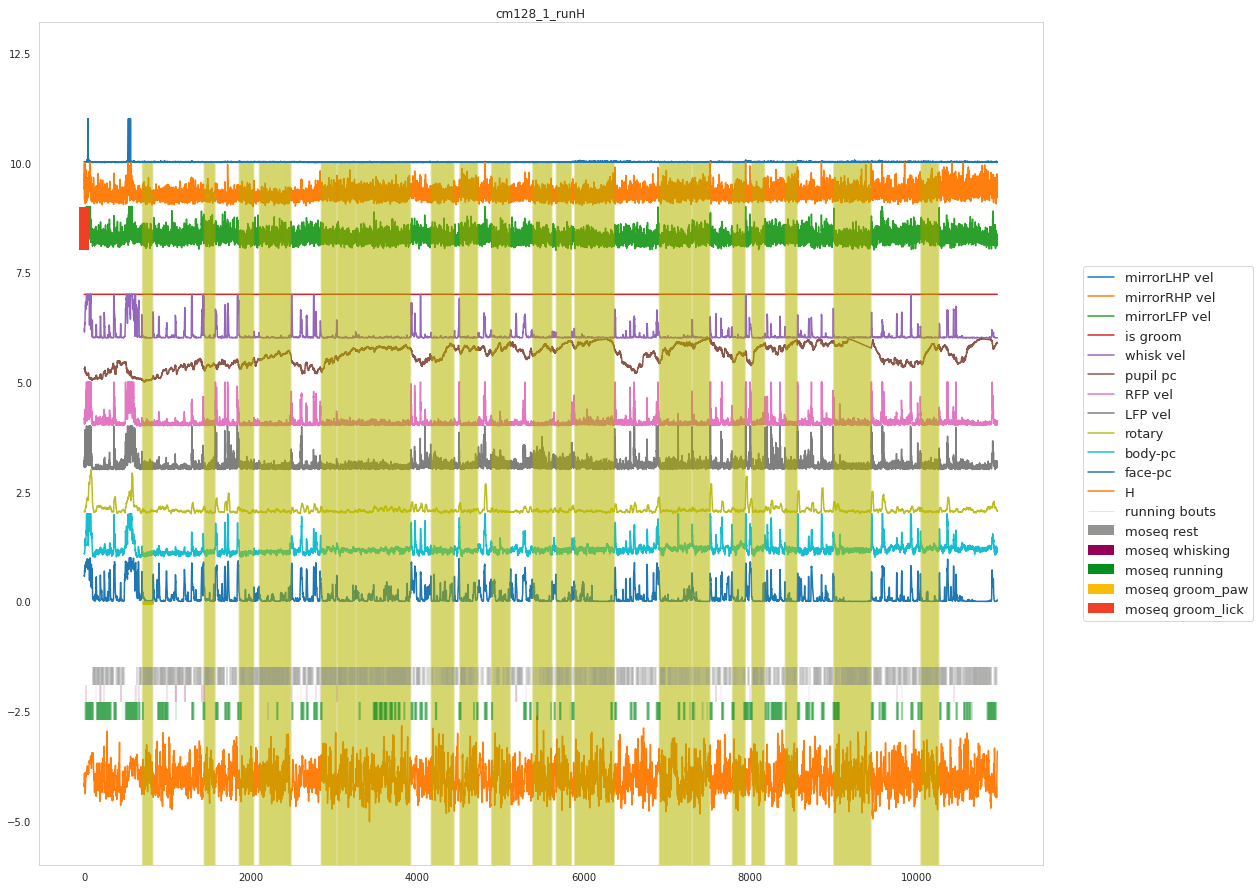

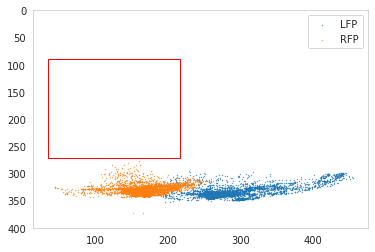

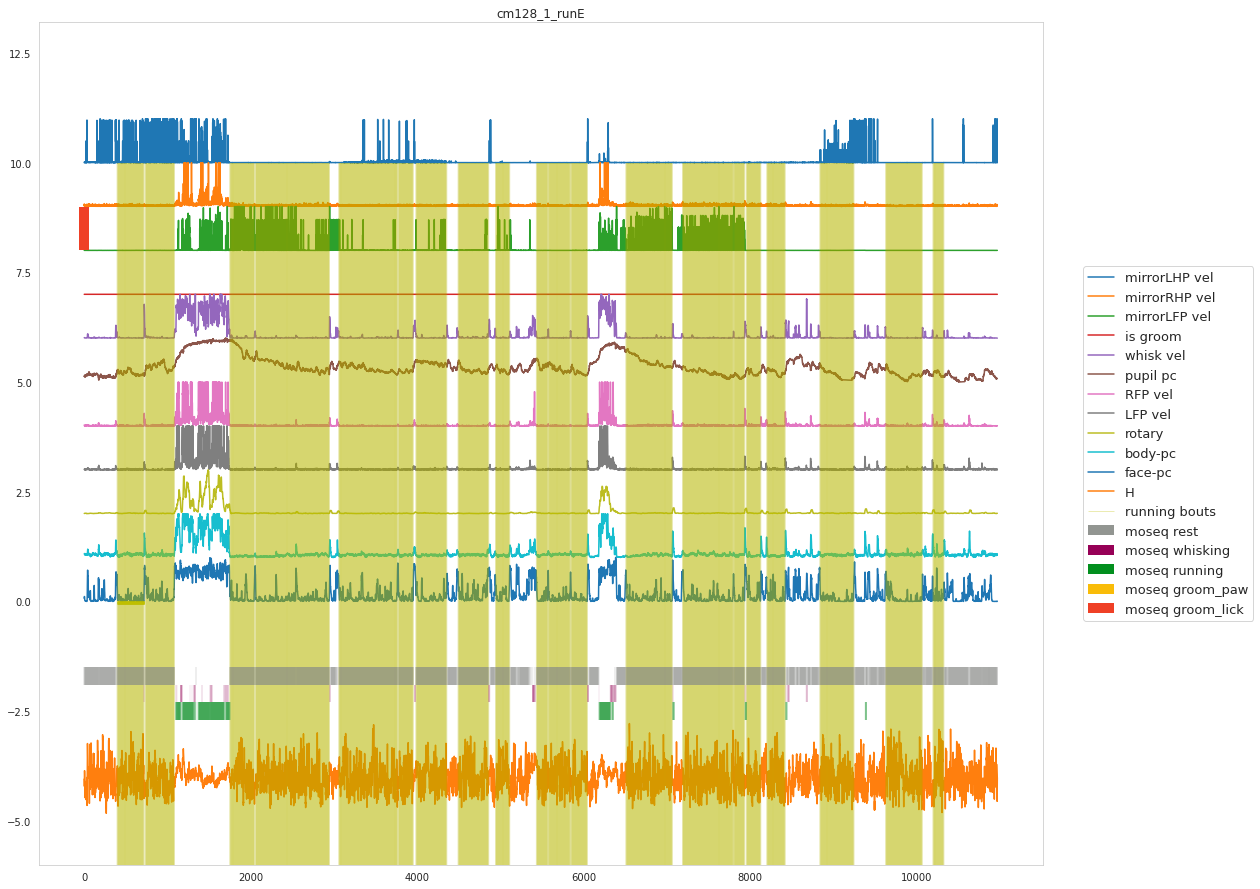

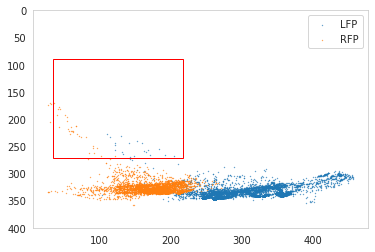

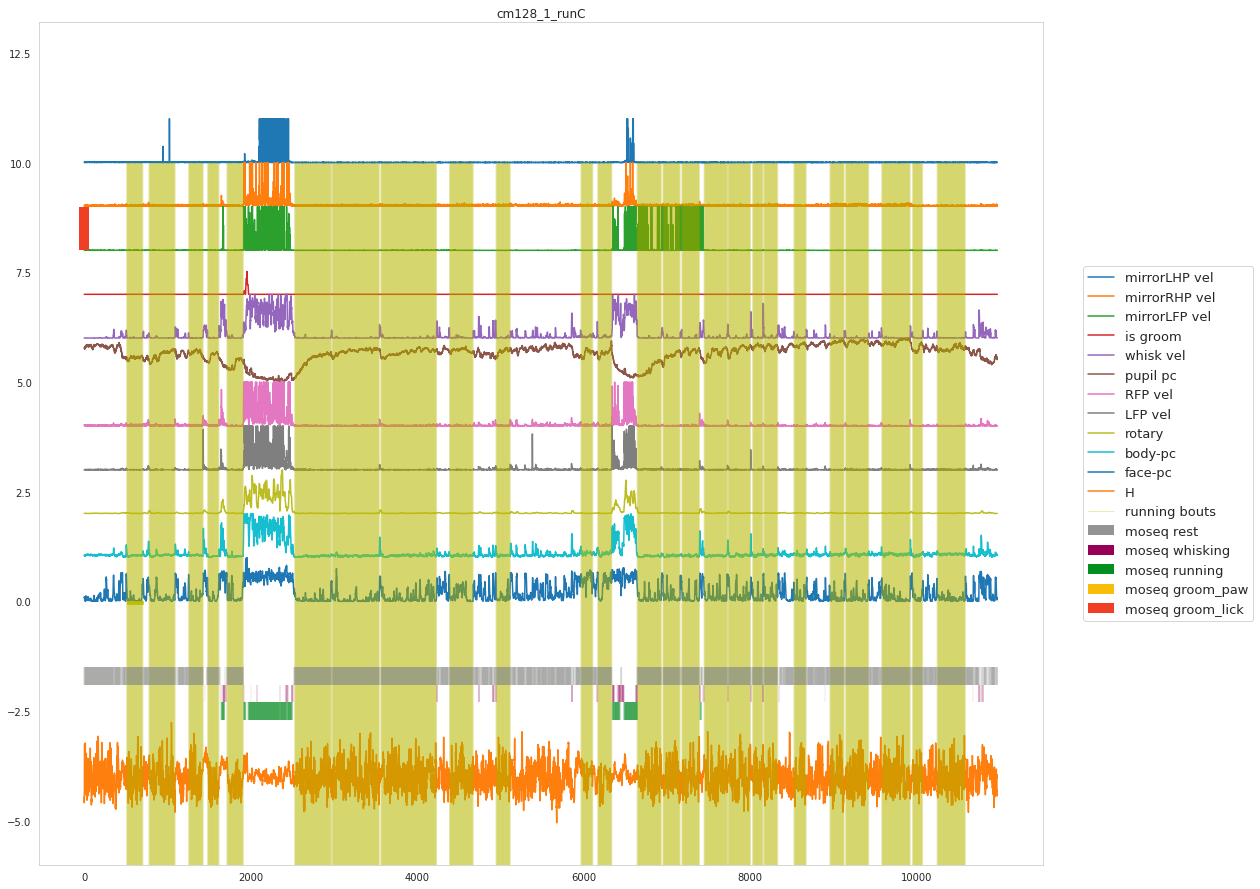

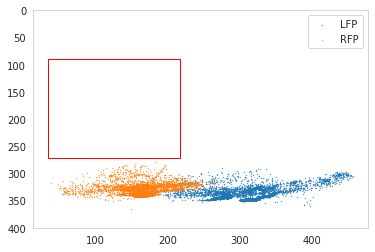

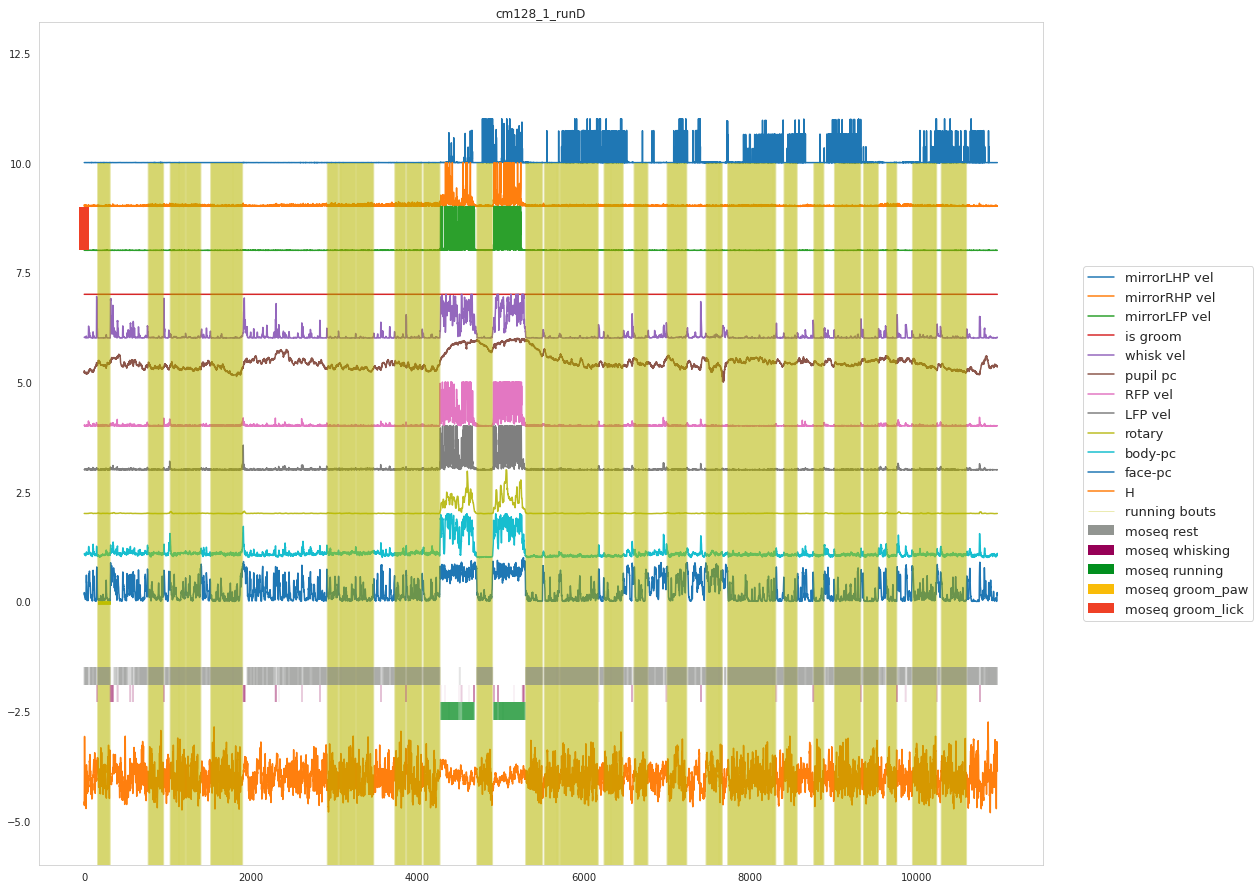

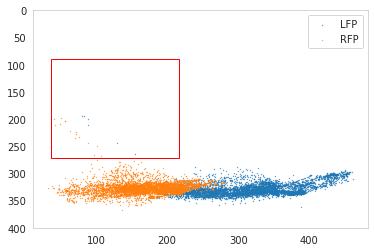

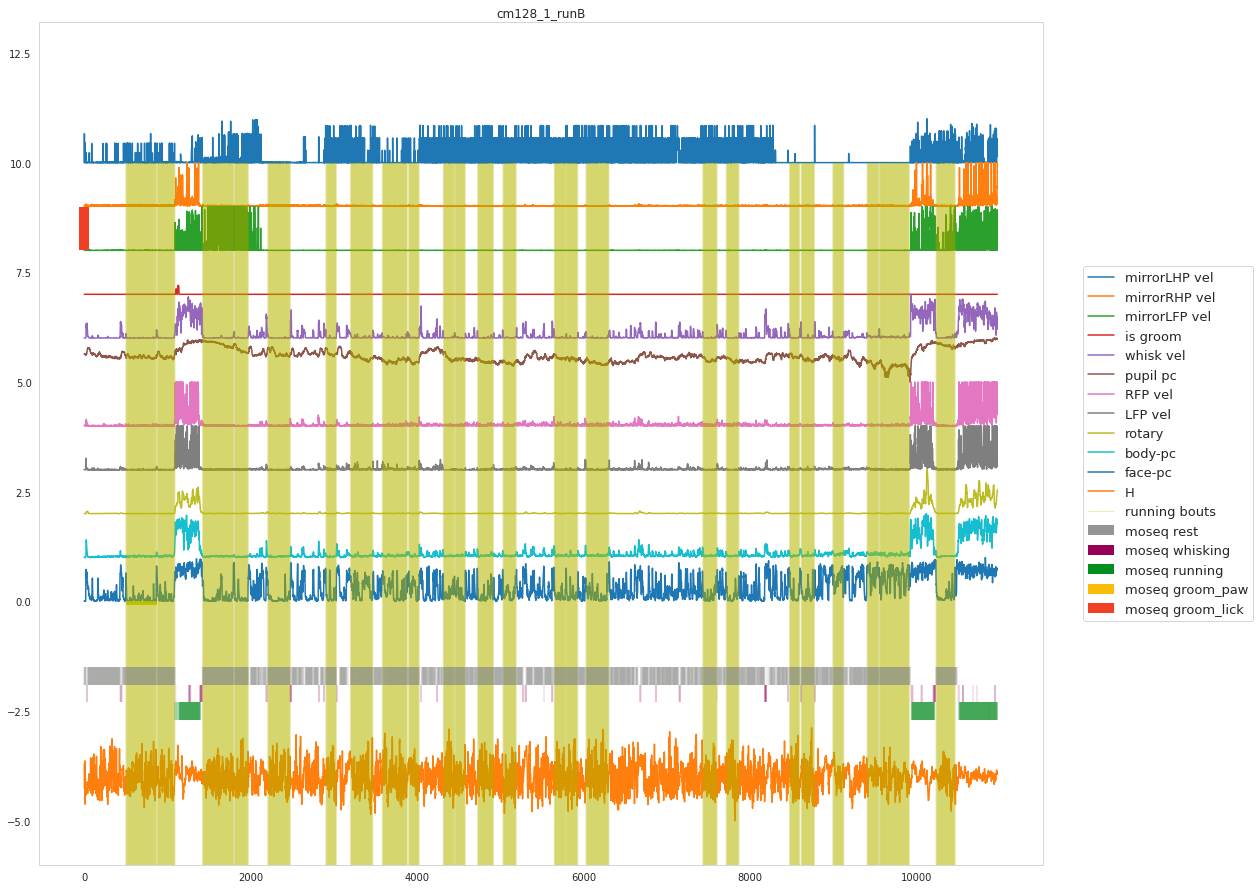

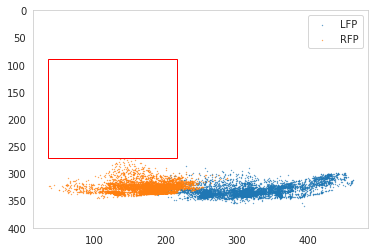

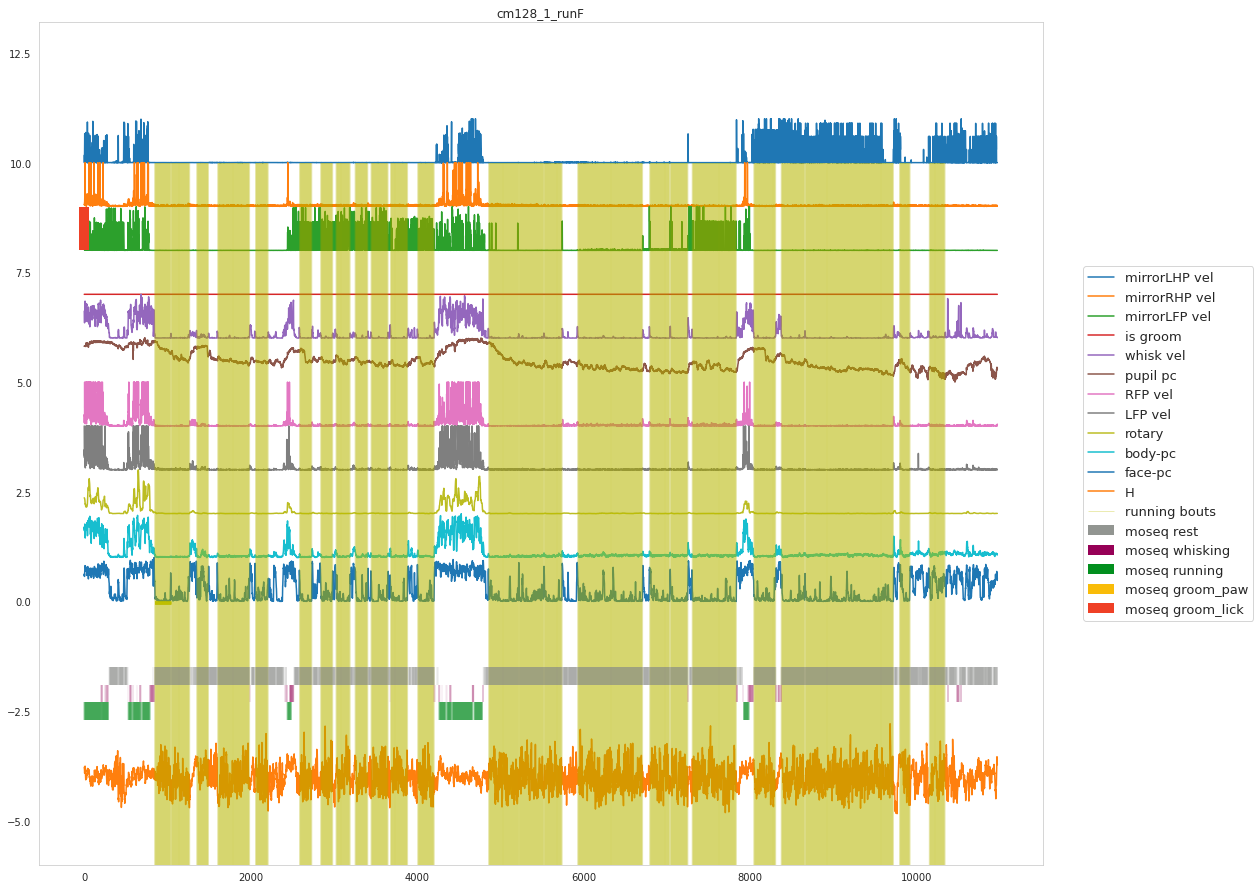

In [8]:
sns.set_style("whitegrid", {'axes.grid' : False})
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

num_regions=500
T_PRE = 100
T_POST = 500
T = T_PRE+T_POST

M_jrgeco = np.empty((num_regions,T,0))
# M_chbt = np.empty((num_regions,T,0))
# M_chbt_std = np.empty((num_regions,T,0))
M_rotf = np.empty((T,0))
M_rotf_raw = np.empty((T,0))
M_pupil_pc = np.empty((T,0))
M_pupil_pc_norm = np.empty((T,0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_whisk_vel = np.empty((T,0))
M_whisk_vel_norm = np.empty((T,0))
M_nose_vel = np.empty((T,0))
M_nose_vel_norm = np.empty((T,0))
M_pupil_p_value = np.empty((T,0))
M_day_label = np.empty((0))
M_is_groom = np.empty((T,0))
M_ind = np.empty((0))
M_ind_stop = np.empty((0))
M_y_rise_LFP = np.empty((T,0))
M_y_rise_LFP_raw = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_LFP_vel_norm = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_RFP_vel_norm = np.empty((T,0))

M_mirrorRFP_vel = np.empty((T,0))
M_mirrorRFP_vel_norm = np.empty((T,0))
M_mirrorLFP_vel = np.empty((T,0))
M_mirrorLFP_vel_norm = np.empty((T,0))
M_mirrorRHP_vel = np.empty((T,0))
M_mirrorRHP_vel_norm = np.empty((T,0))
M_mirrorLHP_vel = np.empty((T,0))
M_mirrorLHP_vel_norm = np.empty((T,0))



data_joint=pd.DataFrame()
big_df_concat = pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    
    ################################### identity 
    run_name = fname.split('_stim_1')[0][-4:]
    day = fname.split('step_2/'+mouse+'/')[1][:1]
    mouse_day = mouse+'_'+day
    run=run_name

    with h5py.File(fname,'r') as f_H: 
        H = np.array(f_H['H']).transpose() #(36,11975)    
        H = H[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

        # H_filt={}
        # H_filt_temp=f_H['H_filt']
        # for i_key, key in enumerate(H_filt_temp.keys()):
        #     H_filt[key] = np.array(H_filt_temp[key]).transpose()[:,500:-505]

    # load pupil 
    try:
        x = scipy.io.loadmat(pupil_path)
        pupil = np.empty((35941,0))
        pupil_p = np.empty((35941,0))
        for key in ['Top']+['TopR']+['Right']+['BottomR']+['Bottom']+['BottomL']+['Left']+['TopL']+['Eyelid']:
            pupil = np.append(pupil,x[mouse_day+'_'+run][key][0,0][:,:2],axis=1)
            pupil_p = np.append(pupil_p,x[mouse_day+'_'+run][key][0,0][:,2:3],axis=1)

        pupil_p_value = np.mean(pupil_p,axis=1)

        pca = PCA(n_components=1)
        pupil_pc = pca.fit_transform(pupil)  
        df = pd.DataFrame(pupil_pc).copy()
        df.iloc[pupil_p_value < 0.5]=np.nan


        pupil_pc = np.array(df.interpolate())
        pupil_pc = np.mean(pupil_pc[:-1].reshape((-1,3)),axis=1)
        pupil_pc = -pupil_pc[500:-505]
        pupil_pc = stats.zscore(pupil_pc)
        pupil_p_value = np.mean(pupil_p_value[:-1].reshape((-1,3)),axis=1)
        pupil_p_value = pupil_p_value[500:-505]

    except:
        print('pupil missing ',mouse_day+'_'+run)
        continue
    
    
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(whisk_dlc_root+'face/' + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(15).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]
        #
        nose_pts=bodyparts[:7]
        nose_vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(nose_pts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            nose_vel_df[bpt] = vel
        mean_nose_vel = nose_vel_df.mean(axis=1)
        smooth_mean_nose_vel = mean_nose_vel.rolling(15).std() # smooth
        smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
        nose_vel = smooth_mean_nose_vel_ds[500:-505]

    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:
        with(h5py.File(pjoin('/home/wx2203/RS_analysis/behavior',
                             mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):
                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                motion_pc[key]= motion_pc[key].iloc[:,:-5]
                
                motion_pc[key] = motion_pc[key].rolling(window=5,axis=1).std()
                motion_pc[key]=motion_pc[key].iloc[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    except:
        continue

        
    # try:    
    f_config = h5py.File(config_root+'groom_config_'+mouse+'.mat','r')

    x_top_left = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,0]
    x_botton_right = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,1]
    y_top_left = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,0]
    y_botton_right = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,1]

    out_h = int((x_botton_right - x_top_left)/3)-20
    out_w = int((y_botton_right - y_top_left)/3) 
    y = int(x_top_left/3)
    x = int(y_top_left/3)

    f_name_dlc = glob.glob(groom_dlc_root +mouse+'/'+ mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
    for i_bpt,bpt in enumerate(bodyparts):

        p_value = new_df[bpt]['likelihood']
        new_df[bpt]['x'][p_value<0.1]=np.nan
        new_df[bpt]['y'][p_value<0.1]=np.nan
        new_df[bpt] = new_df[bpt].interpolate()
        new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel)#.rolling(30).std()
        vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
        paws_vel_df[bpt] = vel[500:-505]
    LFP_vel = np.array(paws_vel_df['LFP'])
    RFP_vel = np.array(paws_vel_df['RFP'])


    fig,ax = plt.subplots(1)
    plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
    plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
    rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
    plt.ylim([0,400])
    plt.legend()
    ax.add_patch(rect)
    plt.gca().invert_yaxis()

    rise_LFP = new_df['LFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
    rise_LFP = np.mean(rise_LFP[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP = rise_LFP[500:-505] 
    # rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

    rise_LFP_raw = new_df['LFP']['y'].copy().diff()
    rise_LFP_raw = np.mean(rise_LFP_raw[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP_raw = rise_LFP_raw[500:-505]   

    is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
    is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
    is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
    is_groom_smooth = is_groom.rolling(50).mean()

    is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    #downsample
    new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
    df_cam0 = new_df.iloc[500:-505]


#     except:
#         print('grooming missing ',mouse_day+'_'+run)   
#         continue
        
    try:
        paws_vel_df = pd.DataFrame()
        f_name_dlc = glob.glob(mirror_dlc_root + mouse_day[2:]+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        #     bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        bodyparts=['LFP','RFP','LHP','RHP']
        for i_bpt,bpt in enumerate(bodyparts):
            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.1]=np.nan
            new_df[bpt]['y'][p_value<0.1]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # nan appears in first few rows
            
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel)#.rolling(60).mean()
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        mirrorLFP_vel = np.array(paws_vel_df['LFP'])
        mirrorRFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLHP_vel = np.array(paws_vel_df['LHP'])
        mirrorRHP_vel = np.array(paws_vel_df['RHP'])
        #downsample
        new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
        df_cam1 = new_df.iloc[500:-505]

    except:
        print('mirror paws velocity missing ',mouse_day+'_'+run)
        continue        
        
    data_pot = pd.concat([df_cam0,df_cam1],
                         keys=['cam0','cam1'],names=['column_level'],axis=1)
    
    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = np.array(stats.zscore(face_pc))
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = np.array(stats.zscore(body_pc))   
    whisk_vel_norm = stats.zscore(whisk_vel)
    nose_vel_norm = stats.zscore(nose_vel)
    pupil_pc_norm = stats.zscore(pupil_pc)
    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)
    data_pot = pd.concat([df_cam0,df_cam1],
                         keys=['cam0','cam1'],names=['column_level'],axis=1)
    # remove extreme values
    threshold = 5
    face_pc[face_pc>threshold]=threshold
    body_pc[body_pc>threshold]=threshold
    whisk_vel_norm[whisk_vel_norm>threshold]=threshold
    nose_vel_norm[nose_vel_norm>threshold]=threshold
    LFP_vel_norm[LFP_vel_norm>threshold]=threshold
    RFP_vel_norm[RFP_vel_norm>threshold]=threshold
    mirrorLFP_vel_norm[mirrorLFP_vel_norm>threshold]=threshold
    mirrorRFP_vel_norm[mirrorRFP_vel_norm>threshold]=threshold
    mirrorLHP_vel_norm[mirrorLHP_vel_norm>threshold]=threshold
    mirrorRHP_vel_norm[mirrorRHP_vel_norm>threshold]=threshold
    
    ################################### rotary (11980, 1)
    try:
        with h5py.File(rotary_root+mouse_day+'_'+run+'_H.mat','r') as f_rot:
            rotf = pd.DataFrame((f_rot['rotf']))#.rolling(window=30,axis=0).std()
            rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   
            rot_raw = np.array(stats.zscore(rotf))
            
            rotf = pd.DataFrame((f_rot['rotf'])).rolling(window=20,axis=0).std()
            rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   
            rot_smooth = np.array(stats.zscore(rotf))
    except:
        print('rotf missing ',mouse_day+'_'+run,' ')
        # No rotf file found? Use LFP_vel_norm instead..
        # rotf = LFP_vel_norm.copy()
        continue

    
    big_df = pd.DataFrame()
    all_bev = ['face_pc','body_pc','whisk_vel_norm','nose_vel_norm',
              'pupil_pc_norm','LFP_vel_norm','RFP_vel_norm','mirrorLFP_vel_norm',
              'mirrorRFP_vel_norm','mirrorLHP_vel_norm','mirrorRHP_vel_norm',
              'rot_raw','rot_smooth']
    for bev in all_bev:
        exec("big_df[bev] = normalize({})".format(bev))
    big_df['rise_LFP']=rise_LFP
    big_df['is_groom_smooth_ds']=is_groom_smooth_ds
    
    #behavior segmentation
    is_whisking = np.logical_and(np.logical_and(big_df['whisk_vel_norm']>0.3, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_smooth']<0.2)
    # is_reach = big_df['rise_LFP']>22
    
    is_running = np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['rot_smooth']>0.1)
    
    is_groom_paw = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['LFP_vel_norm']>0.1),big_df['rot_smooth']<0.2)
    is_groom_lick = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_smooth']<0.2)   
    is_rest = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_smooth']<0.2),big_df['whisk_vel_norm']<0.1)
    
    moseq_list = ['is_rest','is_whisking','is_running','is_groom_paw','is_groom_lick']
    for moseq in moseq_list:
        exec("big_df[moseq] = {}".format(moseq))


    running_ind = np.squeeze(normalize(whisk_vel_norm) < 0.1)

    start_stop_ind = pd.DataFrame(start_stop(np.squeeze(running_ind),trigger_val = True))
    start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
    start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
    start_stop_ind = start_stop_ind.fillna(1000)
    
    # start_stop_ind = start_stop_ind[start_stop_ind['distance_difference']>10]
    start_stop_ind = start_stop_ind[start_stop_ind['duration']>120]
    start_stop_ind = start_stop_ind[start_stop_ind[0]>T_PRE+1]
    start_stop_ind = start_stop_ind[start_stop_ind[0]<10970-(T_PRE+T_POST)]
    
    
    is_groom_start_stop = start_stop(np.squeeze(is_groom_smooth_ds>0.1),trigger_val = True)
    
    temp = []
    for i in range(len(start_stop_ind)):
        x1 = start_stop_ind.iloc[i,0];x2 = start_stop_ind.iloc[i,1];
        temp.append(any(max(x1,lower) <= min(x2,upper) for (lower, upper) in list(is_groom_start_stop)))
    start_stop_ind['is_in_groom']=temp
    start_stop_ind = start_stop_ind[start_stop_ind['is_in_groom']==False]


    tmp = pd.concat([big_df], keys=[mouse_day+'_'+run], names=['row_level'])
    big_df_concat = big_df_concat.append(tmp)

    try:
        plt.figure(figsize=(18,15.5))
        plt.plot(normalize(mirrorLHP_vel_norm)+10,label='mirrorLHP vel')   
        plt.plot(normalize(mirrorRHP_vel_norm)+9,label='mirrorRHP vel') 
        plt.plot(normalize(mirrorLFP_vel_norm)+8,label='mirrorLFP vel') 
        plt.plot(is_groom_smooth_ds+7,label='is groom') 

        plt.plot(normalize(whisk_vel_norm)+6,label='whisk vel') 
        plt.plot(normalize(pupil_pc_norm)+5,label='pupil pc')                           
        plt.plot(normalize(RFP_vel_norm)+4,label='RFP vel')            
        plt.plot(normalize(LFP_vel_norm)+3,label='LFP vel')
        plt.plot(normalize(rot_smooth)+2,label='rotary')
        # plt.plot(normalize(face_pc)+1,label='face-pc')
        plt.plot(normalize(body_pc)+1,label='body-pc')
        plt.plot(normalize(face_pc),label='face-pc')
        # plt.plot(normalize(rise_LFP_raw)-1,label='rise LFP in y')
        plt.plot(H[mouth_S1_ind,:]*9-4,label='H')

        for i in range(len(start_stop_ind)):
            plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
                       -10, 10,linewidth = 0.2,color='y',alpha=0.3)
        plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,1]),
                       -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')
    except:
        print('no start stop found ',mouse_day+'_'+run,' ')
        continue        
    
    # for i_key, key in enumerate(H_filt.keys()):
        # plt.plot(H_filt[key][mouth_S1_ind,:]*9-5-i_key,label="{:.2f}-{:.2f} HZ".format(spectrum[i_key,0],spectrum[i_key,1]))       
    
    col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
    col_list_palette = sns.xkcd_palette(col_list)


    # moseq
    for i, moseq in enumerate(moseq_list):
        plt.vlines(np.where(big_df[moseq]==True), -1.5-i*0.4, -1.9-i*0.4,linewidth=0.1,color=col_list_palette[i])
        plt.vlines(0, 8, 9,linewidth=10,color=col_list_palette[i],label='moseq '+moseq[3:])#for the legend

    plt.ylim([-6,13.2])
    plt.title(mouse_day+'_'+run_name)
    plt.legend(bbox_to_anchor=(1.04,0.5), loc="center left", borderaxespad=0,fontsize = 13)


    for i in range(len(start_stop_ind)):
        M_jrgeco = np.append(M_jrgeco,H[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_jrgeco_std = np.append(M_jrgeco_std,H_std[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_chbt = np.append(M_chbt,H_chbt[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_chbt_std = np.append(M_chbt_std,H_chbt_std[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)

        M_rotf_raw = np.append(M_rotf_raw,rot_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf = np.append(M_rotf,rot_smooth[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_pupil_pc = np.append(M_pupil_pc,pupil_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_face_pc = np.append(M_face_pc,face_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_body_pc = np.append(M_body_pc,body_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel = np.append(M_whisk_vel,whisk_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel_norm = np.append(M_whisk_vel_norm,whisk_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel = np.append(M_nose_vel,nose_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel_norm = np.append(M_nose_vel_norm,nose_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel = np.append(M_LFP_vel,LFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel_norm = np.append(M_LFP_vel_norm,LFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel = np.append(M_RFP_vel,RFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel_norm = np.append(M_RFP_vel_norm,RFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_pupil_pc_norm = np.append(M_pupil_pc_norm,pupil_pc_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)        
        M_pupil_p_value = np.append(M_pupil_p_value,pupil_p_value[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)

        i_bout = M_jrgeco.shape[-1]-1        
        tmp = data_pot[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST]
        tmp = pd.concat([tmp], keys=[i_bout], names=['row_level'])
        data_joint = data_joint.append(tmp)
        
        
        M_mirrorLFP_vel = np.append(M_mirrorLFP_vel,mirrorLFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLFP_vel_norm = np.append(M_mirrorLFP_vel_norm,mirrorLFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel = np.append(M_mirrorRFP_vel,mirrorRFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel_norm = np.append(M_mirrorRFP_vel_norm,mirrorRFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel = np.append(M_mirrorLHP_vel,mirrorLHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel_norm = np.append(M_mirrorLHP_vel_norm,mirrorLHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel = np.append(M_mirrorRHP_vel,mirrorRHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel_norm = np.append(M_mirrorRHP_vel_norm,mirrorRHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)


        M_is_groom = np.append(M_is_groom,is_groom_smooth_ds[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_ind = np.append(M_ind,start_stop_ind.iloc[i,0]*3+1500)
        M_ind_stop = np.append(M_ind_stop,(start_stop_ind.iloc[i,1]+500)*3)     
        
        M_day_label = np.append(M_day_label,mouse_day+'_'+run)
        M_y_rise_LFP = np.append(M_y_rise_LFP,rise_LFP[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_y_rise_LFP_raw = np.append(M_y_rise_LFP_raw,rise_LFP_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
   

In [9]:
M_jrgeco.shape

(500, 600, 530)

In [9]:
M_jrgeco.shape

(500, 700, 77)

# SAVE

In [10]:
scipy.io.savemat(str(PREPARES / "epochs-rest") + "/"+'final_'+mouse+'_raw.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                        'M_pupil_pc':M_pupil_pc,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                        'M_pupil_p_value':M_pupil_p_value,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind':M_ind,
                        'M_ind_stop':M_ind_stop,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                       'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm
                       })



save_pickle(data_joint,str(PREPARES / "epochs-rest") + "/"+'final_'+mouse+'_raw_data_joint')
